<center><h1>HW4</h1></center>
<br>
<br>

Name: Xiaoman Niu
<br>
Github Username: xiaomann339
<br>
USC ID: 6306697960

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Download Data

Package imports

In [1]:
import os,re,glob
import pandas as pd
import numpy as np
from sklearn.feature_selection import f_classif
import matplotlib.pyplot as plt
import seaborn as sns

Get the AReM Data Set

In [2]:
DATA_DIR = "../data/AReM"  
COLS = ["time", "avg_rss12", "var_rss12", "avg_rss13",
        "var_rss13", "avg_rss23", "var_rss23"]

def read_one(path):
    """Read one AReM file: skip '#' comment lines, handle comma/space
    delimiters and trailing commas, and drop the time column."""
    rows = []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = [p for p in re.split(r"[,\s]+", line) if p]
            rows.append([float(p) for p in parts[:7]])
    return pd.DataFrame(rows, columns=COLS).drop(columns="time")

def file_num(path):
    """Extract the integer file index, e.g. 'dataset10.csv' -> 10."""
    return int(re.findall(r"\d+", os.path.basename(path))[0])

records = []
for act in sorted(os.listdir(DATA_DIR)):
    folder = os.path.join(DATA_DIR, act)
    if not os.path.isdir(folder):
        continue 
    for fp in sorted(glob.glob(os.path.join(folder, "dataset*.csv")), key=file_num):
        records.append({
            "activity": act,
            "file_id": file_num(fp),
            "data": read_one(fp),  # 480 x 6 DataFrame
        })

print("Total instances:", len(records))
lengths = pd.Series([len(r["data"]) for r in records])
print("Rows per file:\n", lengths.value_counts())
print("Any missing values:", any(r["data"].isna().any().any() for r in records))


Total instances: 88
Rows per file:
 480    87
479     1
Name: count, dtype: int64
Any missing values: False


In [3]:
short = [(r["activity"], r["file_id"], len(r["data"])) for r in records if len(r["data"]) != 480]
print("Files with fewer than 480 rows:", short)

Files with fewer than 480 rows: [('sitting', 8, 479)]


### (b) Test and Train Data

In [4]:
def is_test(activity, file_id):
    """Return True if this instance belongs to the test set (rule from 1(b))."""
    test_ids = {1, 2} if activity.startswith("bending") else {1, 2, 3}
    return file_id in test_ids

for r in records:
    r["split"] = "test" if is_test(r["activity"], r["file_id"]) else "train"

train_records = [r for r in records if r["split"] == "train"]
test_records  = [r for r in records if r["split"] == "test"]

print("Train instances:", len(train_records))
print("Test instances: ", len(test_records), "\n")
print(pd.crosstab(pd.Series([r["activity"] for r in records], name="activity"),
                  pd.Series([r["split"] for r in records], name="split")))

Train instances: 69
Test instances:  19 

split     test  train
activity             
bending1     2      5
bending2     2      4
cycling      3     12
lying        3     12
sitting      3     12
standing     3     12
walking      3     12


### (c) Feature Extraction

#### i. Research

#####  **Commonly used time-domain features**

**1. Central tendency**
- Mean, median, mode

**2. Dispersion / variability**
- Standard deviation, variance
- Range (max − min), interquartile range (IQR = Q3 − Q1)
- Mean / median absolute deviation (MAD)
- Coefficient of variation (std / mean)

**3. Order statistics**
- Minimum, maximum
- Quartiles (Q1, Q3) and other percentiles (e.g., 10th, 90th)

**4. Distribution shape**
- Skewness (asymmetry of the distribution)
- Kurtosis (heaviness of the tails)

**5. Energy and amplitude**
- Energy (sum of squared values), root mean square (RMS)
- Mean absolute value, peak-to-peak amplitude

**6. Temporal structure / signal change**
- Mean of first differences, waveform length (sum of absolute differences)
- Zero-crossing rate or mean-crossing rate
- Number of peaks
- Autocorrelation at different lags
- Slope of a linear trend fitted over time

**7. Complexity**
- Entropy measures (e.g., sample entropy, approximate entropy)
- Hjorth parameters (activity, mobility, complexity)


#### ii. Extraction

In [5]:
STAT_NAMES = ["min", "max", "mean", "median", "std", "1st_quart", "3rd_quart"]
META_COLS = ["activity", "file_id", "split"]

def series_features(x):
    x = np.asarray(x, dtype=float)
    return {
        "min": x.min(),
        "max": x.max(),
        "mean": x.mean(),
        "median": np.median(x),
        "std": x.std(ddof = 1),
        "1st_quart": np.percentile(x,25),
        "3rd_quart": np.percentile(x,75),
    }
    

def extract_features(records, n_segments = 1):
    rows = []
    for r in records:
        row = {
            "activity": r["activity"],
            "file_id": r["file_id"],
            "split": r["split"]
        }
        values = r["data"].to_numpy()
        segments = np.array_split(values, n_segments, axis = 0)
        for s,seg in enumerate(segments):
            for j in range(seg.shape[1]):
                ts_id = s*seg.shape[1] + j + 1
                for name,val in series_features(seg[:,j]).items():
                    row[f"{name}{ts_id}"] = val
        rows.append(row)

    df = pd.DataFrame(rows)
    df.index = pd.RangeIndex(1, len(df) + 1, name="Instance")
    return df

features = extract_features(records)
feature_cols = [c for c in features.columns if c not in META_COLS]

print("Feature table shape:", features.shape)
print("Number of features:", len(feature_cols))

pd.set_option("display.max_columns", 50)
features.round(3)


Feature table shape: (88, 45)
Number of features: 42


,activity,file_id,split,min1,max1,mean1,median1,std1,1st_quart1,3rd_quart1,min2,max2,mean2,median2,std2,1st_quart2,3rd_quart2,min3,max3,mean3,median3,std3,1st_quart3,3rd_quart3,min4,max4,mean4,median4,std4,1st_quart4,3rd_quart4,min5,max5,mean5,median5,std5,1st_quart5,3rd_quart5,min6,max6,mean6,median6,std6,1st_quart6,3rd_quart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,37.25,45.00,40.625,40.50,1.477,39.25,42.000,0.0,1.30,0.359,0.430,0.323,0.00,0.500,4.00,29.50,19.041,19.250,4.463,16.00,23.250,0.0,7.23,0.833,0.50,0.966,0.000,1.120,27.25,38.25,34.311,35.00,2.188,33.000,36.00,0.00,1.92,0.571,0.43,0.583,0.000,1.300
2,bending1,2,test,38.00,45.67,42.813,42.50,1.436,42.00,43.670,0.0,1.22,0.372,0.470,0.289,0.00,0.500,2.00,29.50,20.097,21.000,3.894,19.00,22.250,0.0,5.76,0.876,0.50,1.047,0.000,1.145,27.67,38.50,33.025,33.00,1.995,32.000,34.50,0.00,3.11,0.571,0.43,0.601,0.000,1.300
3,bending1,3,train,35.00,47.40,43.954,44.33,1.559,43.00,45.000,0.0,1.70,0.426,0.470,0.339,0.00,0.500,6.50,29.75,22.122,23.000,3.031,19.75,24.000,0.0,4.44,0.497,0.43,0.551,0.000,0.830,29.00,38.50,35.588,36.00,2.000,35.362,36.50,0.00,1.79,0.493,0.43,0.514,0.000,0.940
4,bending1,4,train,33.00,47.75,42.180,43.50,3.671,39.15,45.000,0.0,3.00,0.696,0.500,0.631,0.00,1.120,8.50,30.00,22.184,23.000,3.810,20.50,24.372,0.0,5.15,0.990,0.83,0.954,0.430,1.300,20.00,38.67,33.494,35.00,3.849,30.458,36.33,0.00,2.18,0.614,0.50,0.524,0.000,1.000
5,bending1,5,train,33.00,45.75,41.678,41.75,2.243,41.33,42.750,0.0,2.83,0.536,0.500,0.405,0.43,0.710,3.00,28.25,19.007,19.125,4.087,16.50,22.062,0.0,6.42,0.842,0.50,0.929,0.430,1.120,23.67,37.50,29.857,30.00,2.411,28.458,31.25,0.00,1.79,0.383,0.43,0.389,0.000,0.500
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,walking,11,train,19.50,45.33,33.587,34.25,4.651,30.25,37.000,0.0,14.67,4.577,4.260,2.461,2.87,6.105,7.33,23.25,15.318,15.330,2.970,13.25,17.270,0.0,9.00,3.227,3.10,1.647,2.050,4.260,6.33,25.00,15.892,16.00,3.284,13.730,18.25,0.00,8.32,3.260,3.11,1.640,2.050,4.322
85,walking,12,train,19.75,45.50,34.323,35.25,4.752,31.00,38.000,0.0,13.47,4.456,3.900,2.599,2.49,5.970,6.25,22.25,15.210,15.250,2.711,13.50,17.000,0.0,9.00,3.277,3.11,1.500,2.170,4.390,6.25,23.25,15.550,15.75,3.120,13.500,17.75,0.00,9.67,3.433,3.20,1.733,2.157,4.565
86,walking,13,train,19.50,46.00,34.546,35.25,4.842,31.25,37.812,0.0,12.47,4.372,4.135,2.360,2.49,5.800,7.00,22.67,15.186,15.250,2.758,13.25,17.000,0.0,8.34,3.029,2.86,1.665,1.790,4.110,7.00,22.75,15.760,15.75,2.823,14.000,17.75,0.00,10.00,3.338,3.08,1.657,2.160,4.335


#### iii. Standard Deviation

In [6]:
feature_std = features[feature_cols].std(ddof = 1)
feature_std.round(4)

min1          9.5700
max1          4.3944
mean1         5.3357
median1       5.4401
std1          1.7722
1st_quart1    6.1536
3rd_quart1    5.1389
min2          0.0000
max2          5.0627
mean2         1.5742
median2       1.4122
std2          0.8841
1st_quart2    0.9464
3rd_quart2    2.1253
min3          2.9565
max3          4.8751
mean3         4.0084
median3       4.0364
std3          0.9467
1st_quart3    4.2207
3rd_quart3    4.1716
min4          0.0000
max4          2.1836
mean4         1.1661
median4       1.1456
std4          0.4582
1st_quart4    0.8436
3rd_quart4    1.5525
min5          6.1240
max5          5.7412
mean5         5.6756
median5       5.8138
std5          1.0249
1st_quart5    6.0965
3rd_quart5    5.5317
min6          0.0458
max6          2.5189
mean6         1.1548
median6       1.0865
std6          0.5176
1st_quart6    0.7586
3rd_quart6    1.5236
dtype: float64

In [7]:
def bootstrap_std_ci(x, n_boot = 1000, alpha = 0.10, seed = 56):
    rng = np.random.default_rng(seed)
    x =  np.asarray(x, dtype = float)
    n = len(x)
    
    boot_stds = np.empty(n_boot)
    for b in range(n_boot):
        sample = rng.choice(x, size = n, replace = True)
        boot_stds[b] = sample.std(ddof = 1)
        
    lower = np.percentile(boot_stds, 100*alpha/2)
    upper = np.percentile(boot_stds, 100*(1-alpha/2))
    return x.std(ddof = 1), lower, upper 


ci_rows = []
for col in feature_cols:
    s, lo, up = bootstrap_std_ci(features[col])
    ci_rows.append({"feature": col, "std": s, "CI_lower": lo, "CI_upper":up})

ci_table = pd.DataFrame(ci_rows).set_index("feature")
ci_table.round(4)

,std,CI_lower,CI_upper
feature,,,
min1,9.5700,8.1855,10.8147
max1,4.3944,3.3055,5.3035
mean1,5.3357,4.6563,5.8797
median1,5.4401,4.7462,6.0191
std1,1.7722,1.5631,1.9515
1st_quart1,6.1536,5.5452,6.6421
3rd_quart1,5.1389,4.2475,5.8292
min2,0.0000,0.0000,0.0000
max2,5.0627,4.6318,5.3853


#### iv. Select Features

In [8]:
train_feat = features[features["split"] == "train"]
X_train = train_feat[feature_cols]
y_train = train_feat["activity"]

F, p = f_classif(X_train, y_train)

f_scores = pd.Series(F, index = feature_cols ).fillna(0)
f_scores.sort_values(ascending = False).round(2)

f_df = pd.DataFrame({
    "stat":   [c[:-1] for c in f_scores.index],       
    "series": [int(c[-1]) for c in f_scores.index],   
    "F":      f_scores.values,
})

f_table = f_df.pivot(index="stat", columns="series", values="F").loc[STAT_NAMES]
f_table.round(2)

f_rank = f_table.rank(axis=0, ascending=False)   # rank the 7 statistics within each series (1 = best)
f_rank["mean_rank"] = f_rank.mean(axis=1)        # average rank of each statistic over the 6 series
f_rank.sort_values("mean_rank")

/Users/non-sense/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:110: UserWarning: Features [ 7 21] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/Users/non-sense/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/feature_selection/_univariate_selection.py:111: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


series,1,2,3,4,5,6,mean_rank
stat,,,,,,,
mean,3.0,1.0,3.0,2.0,2.0,2.0,2.166667
3rd_quart,6.0,2.0,2.0,3.0,3.0,1.0,2.833333
median,2.0,3.0,6.0,1.0,4.0,3.0,3.166667
1st_quart,1.0,5.0,5.0,4.0,5.0,4.0,4.000000
max,7.0,6.0,1.0,6.0,1.0,6.0,4.500000
std,5.0,4.0,7.0,5.0,7.0,5.0,5.500000
min,4.0,7.0,4.0,7.0,6.0,7.0,5.833333


In [9]:
corrs = []
for k in range(1, 7):
    cols = [f"{s}{k}" for s in STAT_NAMES]
    c = X_train[cols].corr()
    c.index = STAT_NAMES
    c.columns = STAT_NAMES
    corrs.append(c)

avg_corr = pd.concat(corrs).groupby(level=0).mean().loc[STAT_NAMES, STAT_NAMES]
avg_corr.round(2)

,min,max,mean,median,std,1st_quart,3rd_quart
min,1.00,0.36,0.59,0.57,-0.32,0.60,0.52
max,0.36,1.00,0.79,0.75,0.63,0.71,0.82
mean,0.59,0.79,1.00,0.99,0.38,0.98,0.98
median,0.57,0.75,0.99,1.00,0.36,0.98,0.96
std,-0.32,0.63,0.38,0.36,1.00,0.28,0.50
1st_quart,0.60,0.71,0.98,0.98,0.28,1.00,0.93
3rd_quart,0.52,0.82,0.98,0.96,0.50,0.93,1.00


**Selected features: 
mean, standard deviation, and maximum.**

To judge which features are most useful for distinguishing activities, we
computed the one-way ANOVA F-statistic of each of the 42 features on the
**training set only** (to avoid using test data in a modeling decision).
A larger F means a larger difference between activity means relative to the
spread within each activity. Because F-values from the variance series
(2, 4, 6) are much larger than those from the average series (1, 3, 5),
we ranked the 7 statistics within each series and averaged the ranks.
We also computed the average correlation between the statistics across the
6 series to check for redundancy.

Findings:
- **mean** has the best average rank (2.17) and is in the top 3 for every
  series, making it the most consistent feature.
- mean, median, 1st quartile, and 3rd quartile are almost perfectly
  correlated (r ≥ 0.98). They carry nearly the same information, so only one
  of them (mean) is kept.
- **std** has the lowest correlation with mean (r = 0.38), so it adds
  complementary information about variability. Its F-values on the variance
  series are high (about 129–361), higher than those of any max feature,
  although its within-series rank appears low because the location
  statistics on these series are even stronger.
- **max** ranks first on series 3 and 5 (avg_rss13, avg_rss23), where mean and
  std are weaker, and is only moderately correlated with mean (0.79) and std
  (0.63).
- **min** is the weakest statistic (average rank 5.83). On the variance series
  it is almost always 0, and `min2` and `min4` are constant across all
  instances, so it is not selected.

Therefore, mean, std, and max are chosen because together they describe three
different aspects of each time series: its location, its variability, and its
extreme values.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

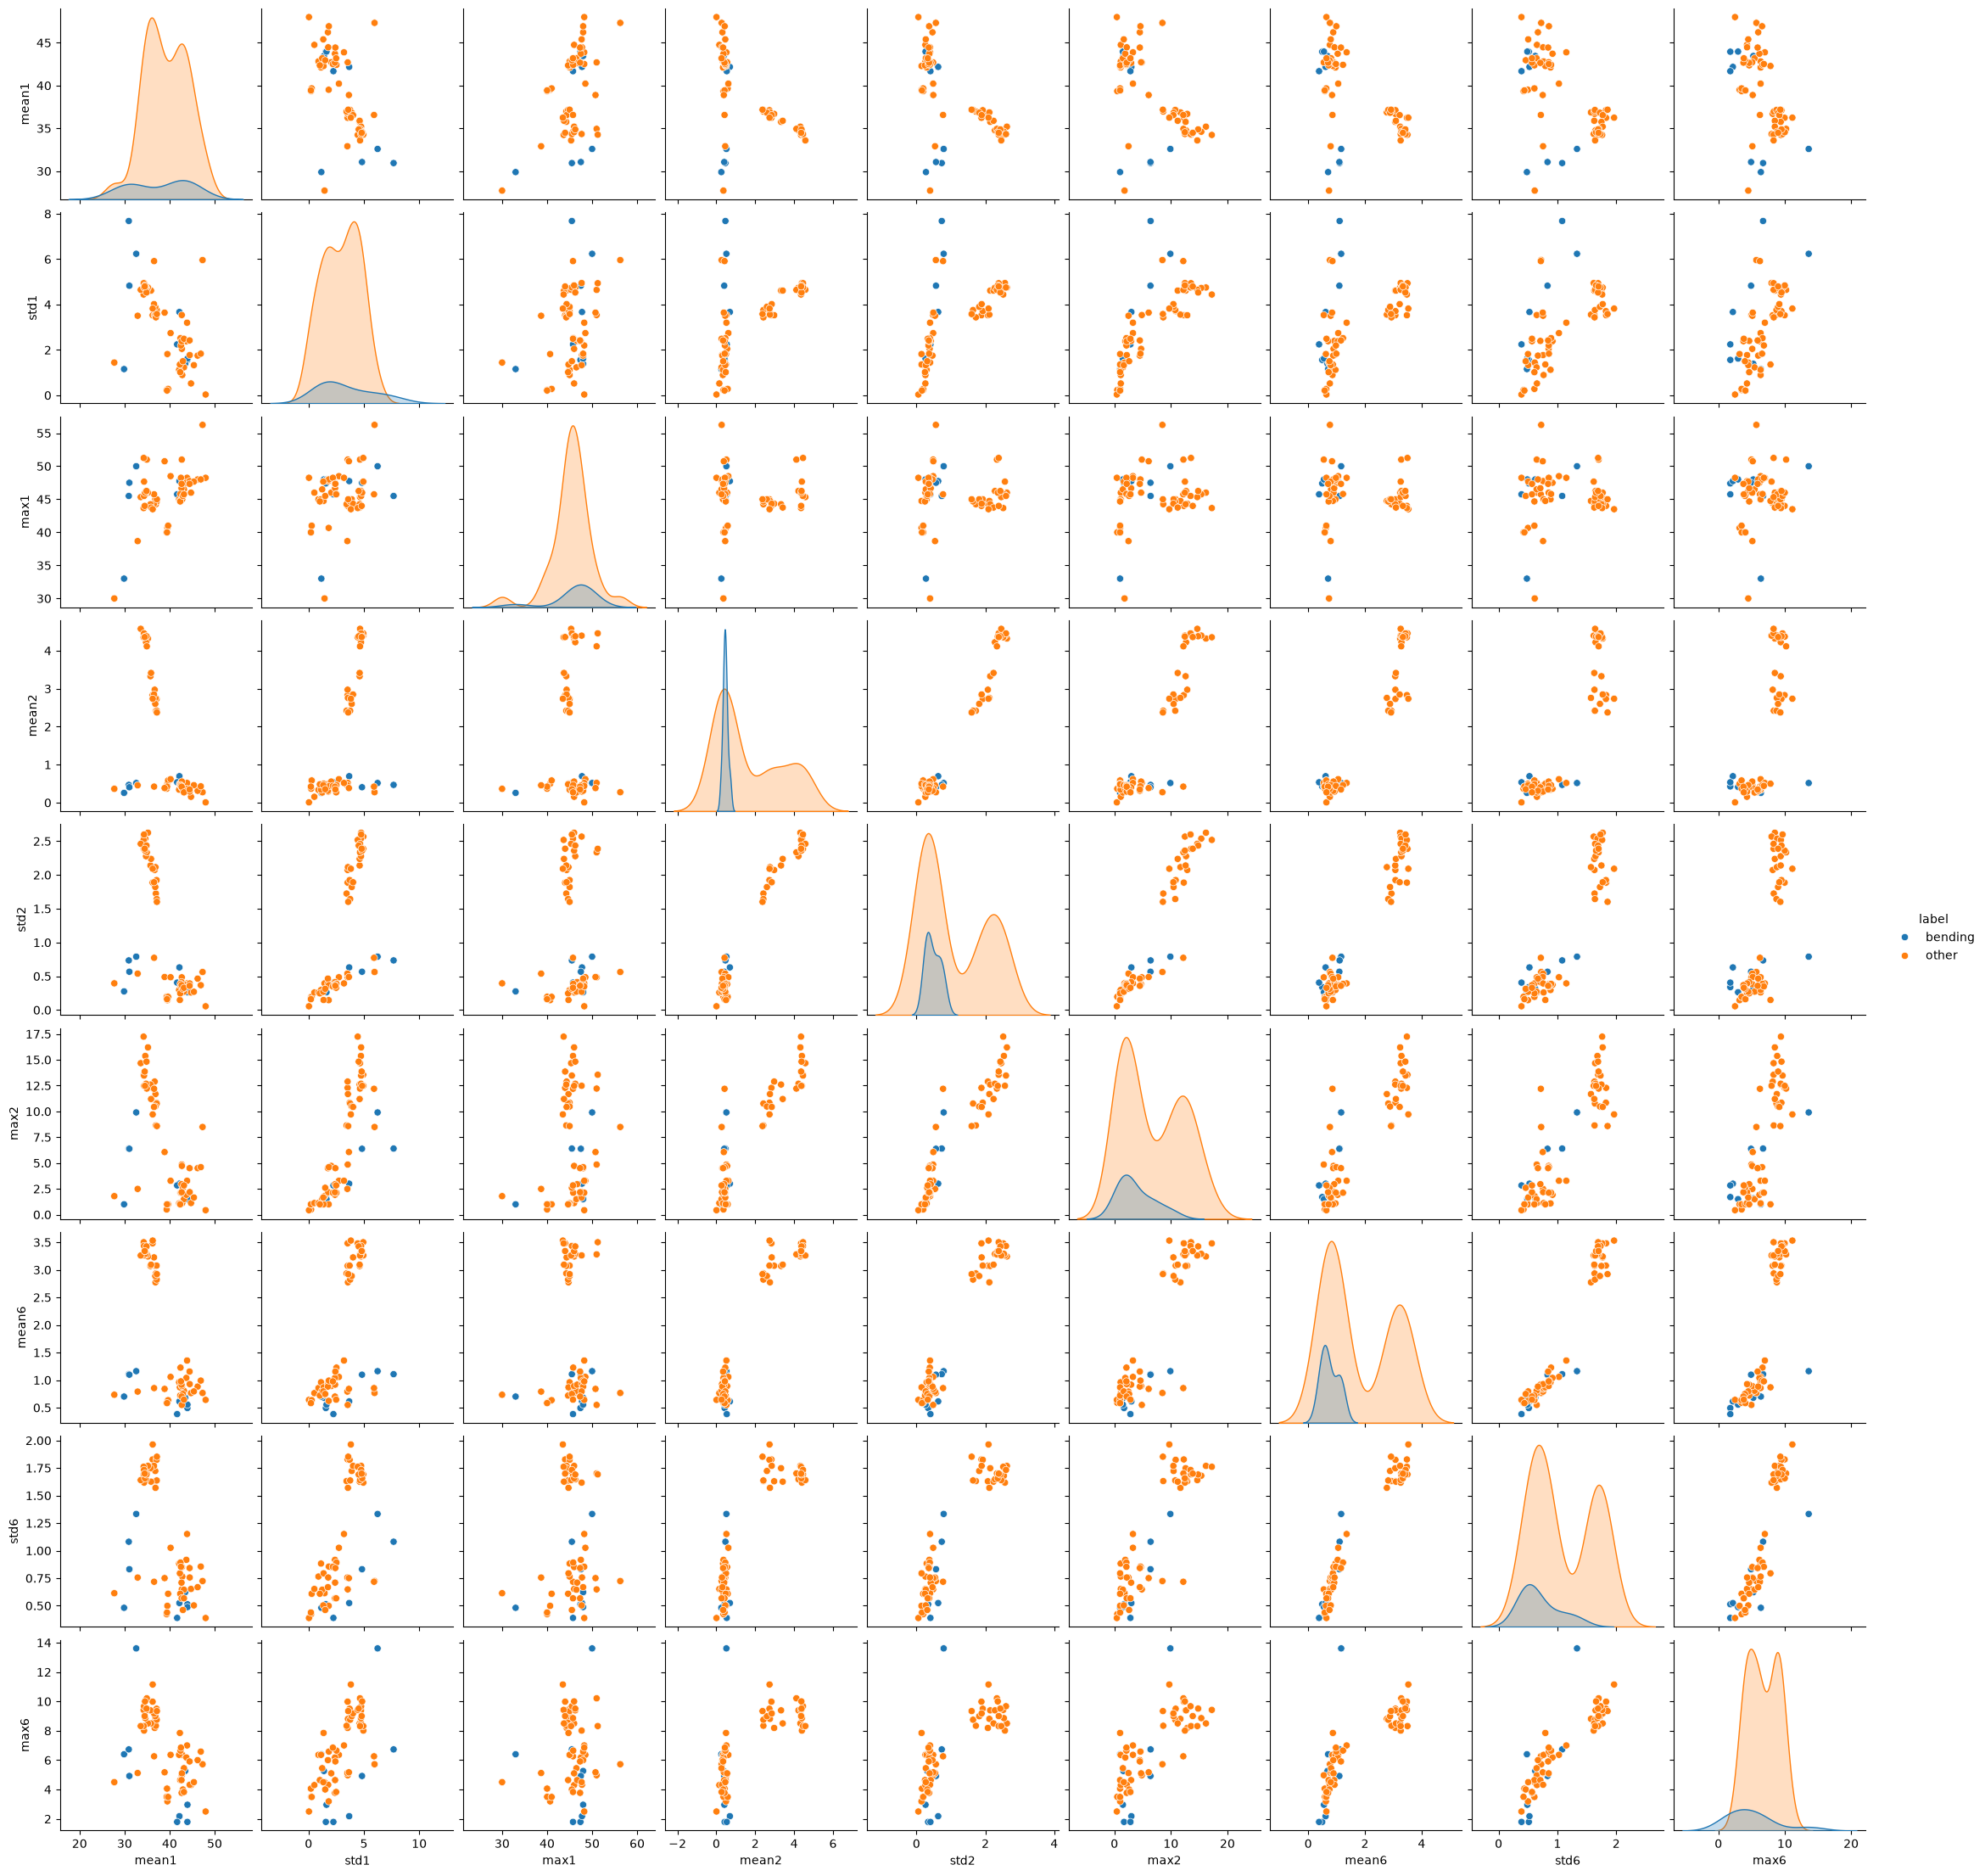

In [10]:
# construct the label of binary classification: bending vs. other

selected_stats = ["mean", "std", "max"] #features we selected in homework3

train_feat = features[features["split"] == "train"].copy()
train_feat["label"] = np.where(train_feat["activity"].str.startswith("bending"),"bending","other")

train_feat["label"].value_counts()

cols = ["mean1", "std1", "max1", "mean2", "std2", "max2", "mean6", "std6", "max6"]
sns.pairplot(train_feat, vars=cols, hue="label")

**Observations.**

- No single feature separates bending from the other activities. On the
  diagonal plots, the distribution of bending overlaps with that of the
  "other" class for every feature.
- In the variance-series features (e.g. `mean2`, `std2`, `mean6`, `std6`),
  the "other" class shows two peaks: one near 0 and one at larger values.
  This suggests that the "other" class contains activities with quite
  different signal behavior. All bending instances fall within the low peak,
  so these features can separate bending from the instances in the high peak,
  but not from those in the low peak.
- No pair of features separates the two classes with a straight line.
  In the plots involving `mean1`, a few bending instances (around 30–33)
  lie away from most other points, but the remaining bending instances
  overlap with the "other" class.
- The bending points are few and scattered. There are only 9 bending
  instances compared with 60 "other" instances, so the classes are
  imbalanced.

#### ii. Splitted Plots

(88, 87)


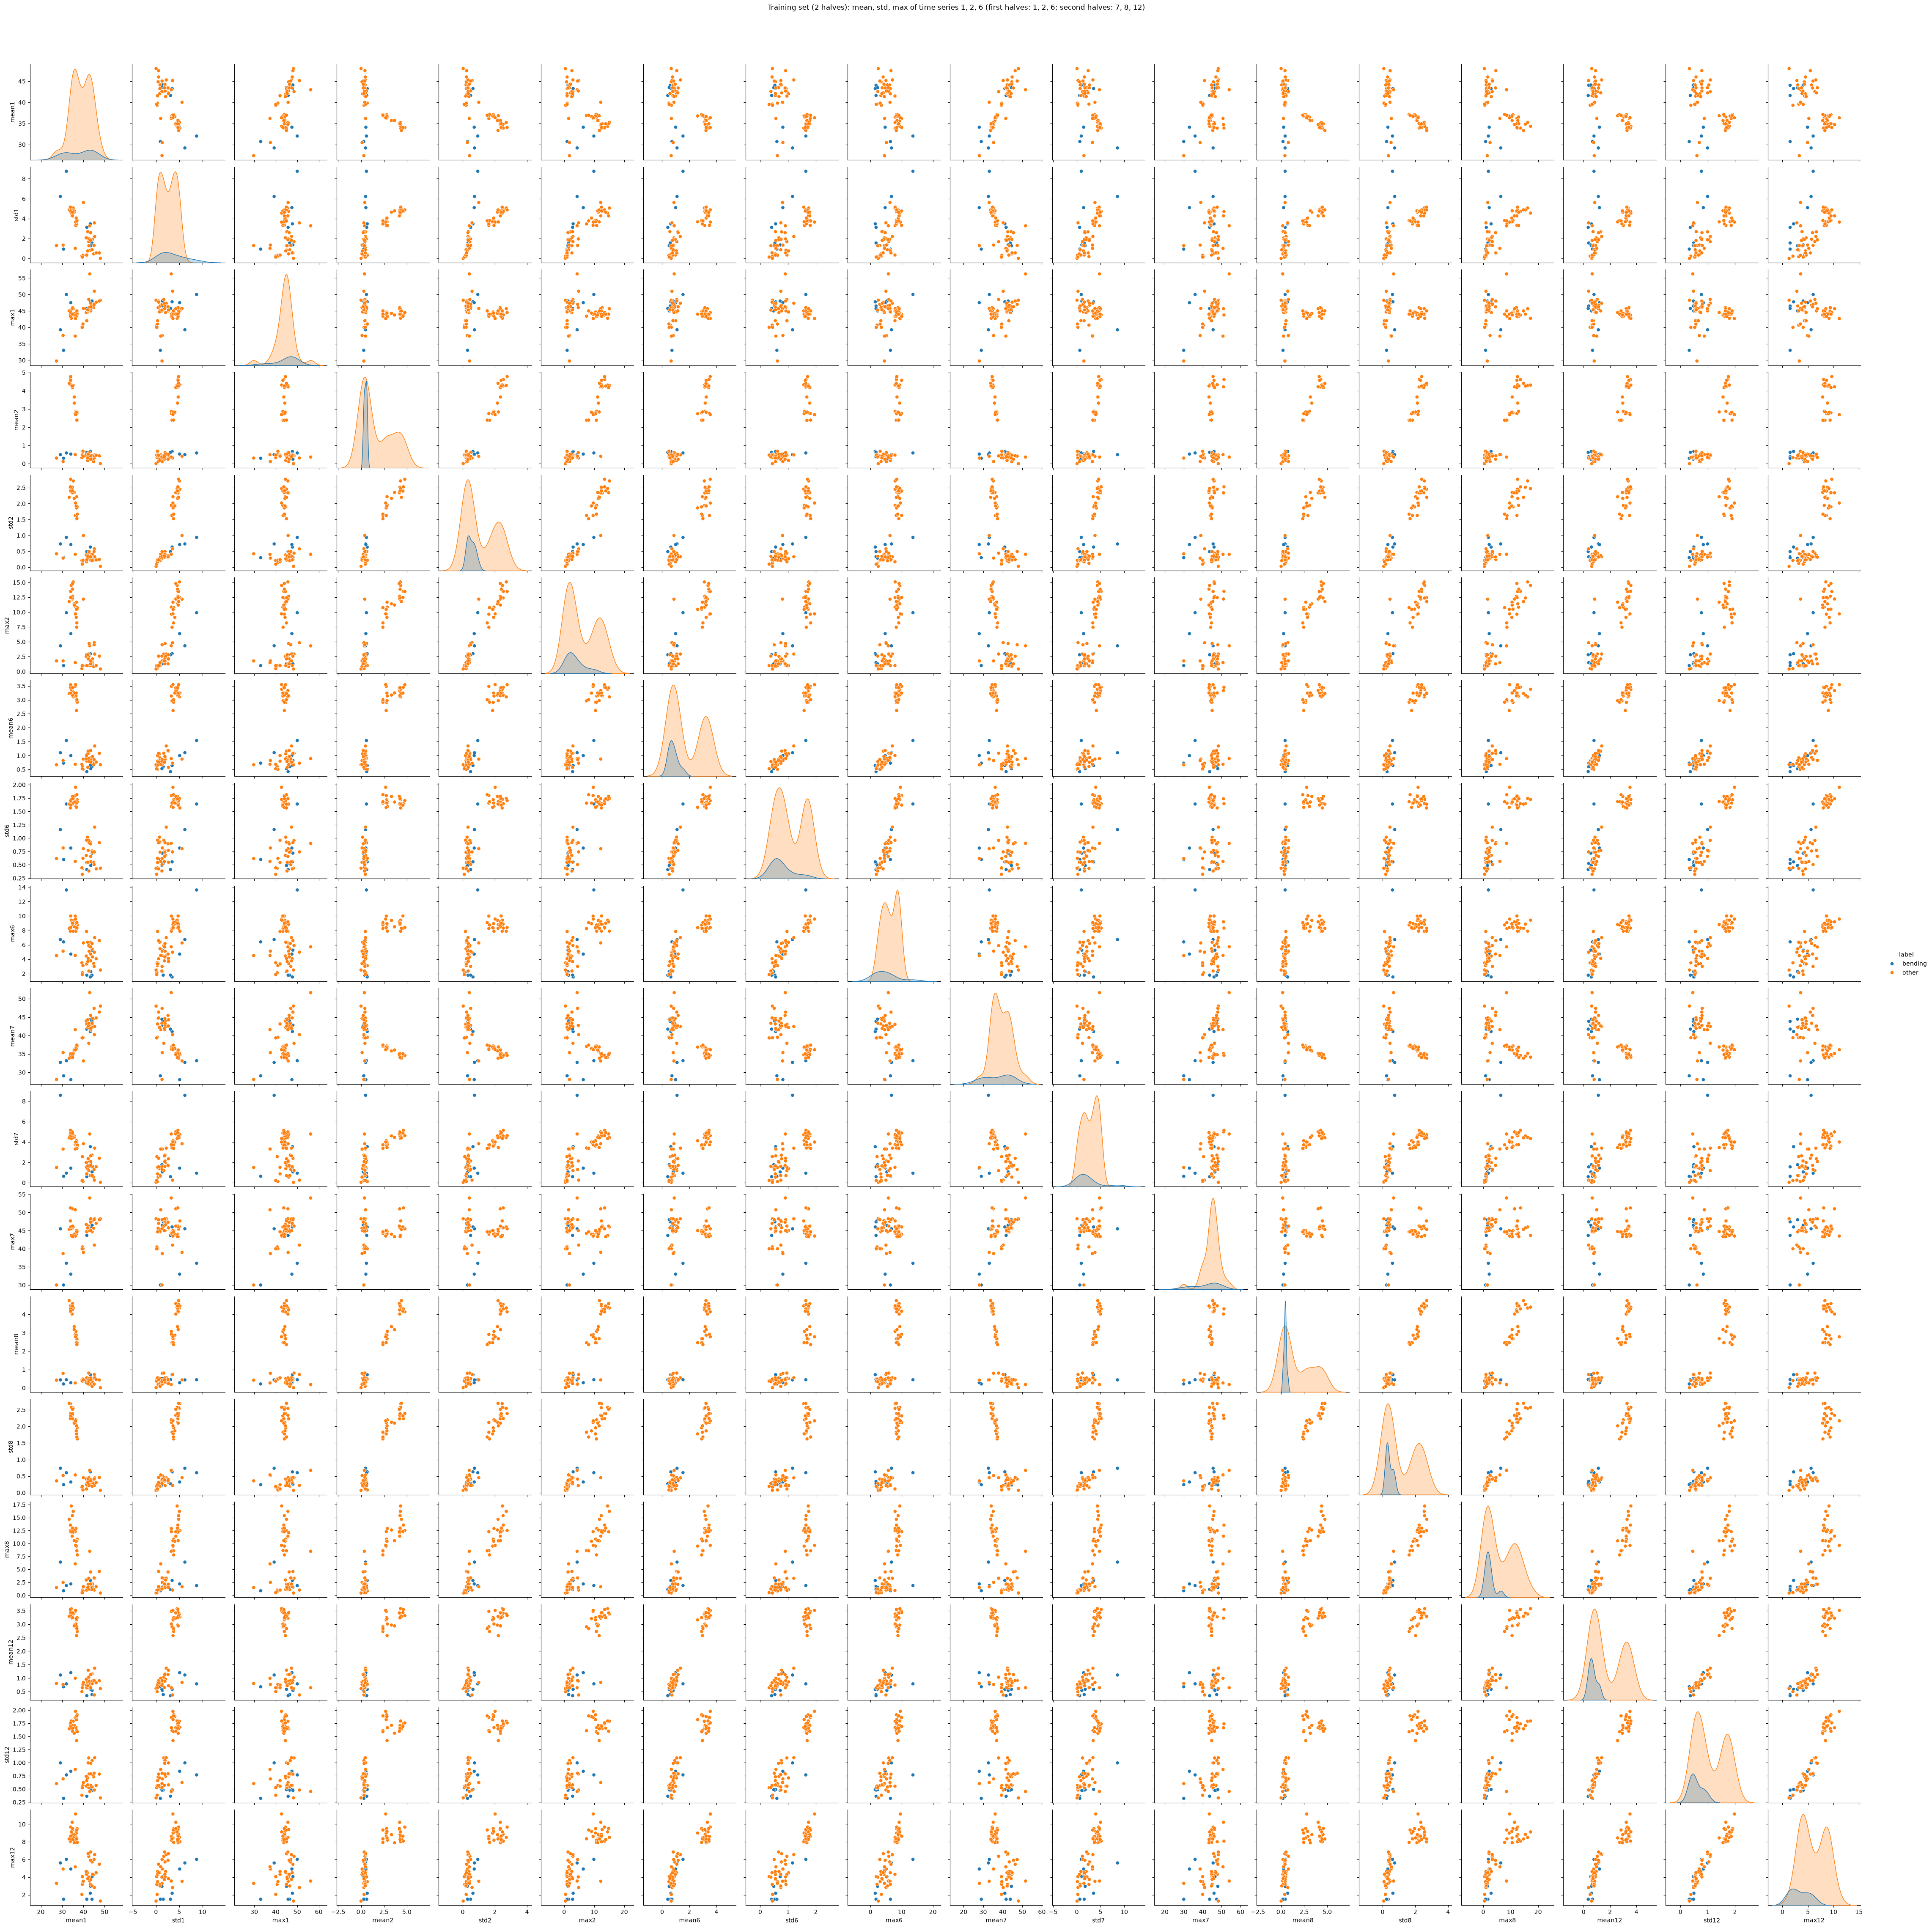

In [11]:
features_seg2 = extract_features(records, n_segments = 2)
print(features_seg2.shape) # 84 features(with 2 segments of time series) and 3 meta colunms (activity , files, split) 

train_feature2 = features_seg2[features_seg2["split"] == "train"].copy()
train_feature2["label"] = np.where(train_feature2["activity"].str.startswith("bending"),
                                "bending", "other")
train_feature2["label"].value_counts()

cols2 = ["mean1", "std1", "max1",       
         "mean2", "std2", "max2",       
         "mean6", "std6", "max6",       
         "mean7", "std7", "max7",       
         "mean8", "std8", "max8",       
         "mean12", "std12", "max12"]    

g = sns.pairplot(train_feature2, vars=cols2, hue="label")
g.fig.suptitle("Training set (2 halves): mean, std, max of time series 1, 2, 6 "
               "(first halves: 1, 2, 6; second halves: 7, 8, 12)", y=1.02)
plt.show()

In [12]:
for a, b in [("mean1", "mean7"), ("mean2", "mean8"), ("mean6", "mean12"),
             ("std1", "std7"),   ("std2", "std8"),   ("std6", "std12"),
             ("max1", "max7"),   ("max2", "max8"),   ("max6", "max12")]:
    r = train_feature2[a].corr(train_feature2[b])
    print(f"{a} vs {b}: r = {r:.2f}")

mean1 vs mean7: r = 0.88
mean2 vs mean8: r = 0.99
mean6 vs mean12: r = 0.98
std1 vs std7: r = 0.70
std2 vs std8: r = 0.98
std6 vs std12: r = 0.93
max1 vs max7: r = 0.66
max2 vs max8: r = 0.89
max6 vs max12: r = 0.80


**Observations.**

Overall, the results are similar to those in 2(a)i, and we do not see a
considerable difference in how well the two classes can be separated.

- The features of both halves show the same general patterns as in 2(a)i.
  For example, in the variance-series features the "other" class still shows
  two peaks, and the bending instances still fall within the low peak.
- The two halves of the same series usually have similar feature values.
  The correlations between corresponding features of the two halves are
  0.88–0.99 for `mean`, 0.70–0.98 for `std`, and 0.66–0.89 for `max`.
  The correlations are lowest for series 1 (avg_rss12), so this series changes
  more between the two halves than the two variance series do.
- The points look slightly more spread out, especially for `max` and `std`,
  which also have the lowest correlations between halves. This is expected,
  since each half contains only about 240 values, so the features are
  computed from less data and are noisier.
- As in 2(a)i, no pair of features separates the two classes with a straight
  line.


#### iii. Time Series Segments

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score


# split The time series by l, get different numbers of features.
def get_xy(l, split = "train"):
    """Split each series into l parts and return the feature matrix X
    (mean, std, max only) and the binary label y (1 = bending, 0 = other)."""
    feat = extract_features(records, n_segments = l)
    feat = feat[feat["split"] == split]
    cols = [ c for c in feat.columns if re.sub(r"\d+$", "", c ) in selected_stats ]  # get mean、std、max 
    X = feat[cols]  # construct new xy
    y = feat["activity"].str.startswith("bending").astype(int) # bending as 1, others as 0
    return X,y

In [14]:
#TEST for get_xy
for l in [ 1, 2, 20]:
    X,y = get_xy(l)
    print(f"l = {l:2d}: X shape = {X.shape}, number of bending = {y.sum()}")

l =  1: X shape = (69, 18), number of bending = 9
l =  2: X shape = (69, 36), number of bending = 9
l = 20: X shape = (69, 360), number of bending = 9


In [15]:
# run the pipeline for 5 fold CV


X,y = get_xy(1)

skf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 56)

# C=np.inf removes regularization (plain logistic regression).
# In scikit-learn >= 1.8, penalty=None is deprecated and C=np.inf is the recommended way,so we use C=np.inf

pipe = Pipeline([
    ("scale", StandardScaler()),
    ("rfe", RFE(LogisticRegression(C=np.inf, max_iter = 1000), n_features_to_select = 5)),
    ("clf", LogisticRegression(C=np.inf, max_iter = 1000)),
     ])

scores = cross_val_score(pipe, X, y, cv = skf,  scoring = "accuracy")
print("Accuracy of each fold:", scores.round(3))
print("Mean CV accuracy:", scores.mean().round(4))

Accuracy of each fold: [0.929 1.    1.    1.    0.923]
Mean CV accuracy: 0.9703


In [16]:
import warnings
from sklearn.exceptions import ConvergenceWarning

**Range of p.** For each l, the number of features is 18l (3 statistics ×
6 series × l segments), and p is tried from 1 to min(20, 18l).
The upper limit of 20 is a judgement rather than a value derived from a formula:

- In 5-fold CV, each training fold has only about 55 instances. With no
  regularization, a logistic regression with a number of parameters close to
  the number of instances can separate the training data perfectly, so its
  coefficients become unstable and the results are not meaningful. p = 20 is
  well below 55.
- The minority class is very small: each training fold contains only about
  7 bending instances. A common rule of thumb for logistic regression is to
  have at least 10 events of the minority class per feature (Peduzzi et al.,
  1996), so even a moderate number of features already risks overfitting.
- Limiting p also keeps the computation manageable.

After the search, we check whether the best p lies at the boundary (p = 20).
If it does not, the upper limit did not affect the result.

In [17]:
# Upper limit of p. Each training fold has only ~55 instances (~7 bending),
# so models with many more features would overfit and the unregularized
# logistic regression would become unstable. p is tried from 1 to min(P_MAX, 18l).

P_MAX = 20
rows = [] 

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    
    for l in range(1,21):
        X,y = get_xy(l)
        X,y = X.to_numpy(), y.to_numpy()
        p_values = range(1, min(P_MAX, X.shape[1])+1) 
        fold_acc = {p: [] for p in p_values}  # accuracies of the 5 folds for each p
        
        for train_idx, val_idx in skf.split(X,y):
            scaler = StandardScaler().fit(X[train_idx])
            X_tr, X_val = scaler.transform(X[train_idx]), scaler.transform(X[val_idx])
            y_tr, y_val = y[train_idx], y[val_idx]
            rfe = RFE(LogisticRegression(C = np.inf, max_iter = 1000), n_features_to_select = 1).fit(X_tr, y_tr)
            order = np.argsort(rfe.ranking_)

            for p in p_values:
                sel = order[:p]
                clf =  LogisticRegression(C=np.inf, max_iter=1000).fit(X_tr[:, sel], y_tr)
                fold_acc[p].append(clf.score(X_val[:, sel], y_val))

        for p in p_values:
            rows.append({"l": l, "p": p, "cv_acc": np.mean(fold_acc[p])})

        
cv_results = pd.DataFrame(rows)
cv_results.shape

(398, 3)

In [18]:
# test
cv_results[(cv_results["l"] == 1) & (cv_results["p"] == 5)]

,l,p,cv_acc
4,1,5,0.97033


In [19]:
cv_results.sort_values("cv_acc", ascending=False).head(10)

,l,p,cv_acc
187,10,10,0.985714
193,10,16,0.985714
186,10,9,0.985714
188,10,11,0.985714
189,10,12,0.985714
190,10,13,0.985714
191,10,14,0.985714
288,15,11,0.985714
192,10,15,0.985714
194,10,17,0.985714


In [20]:
best = cv_results.sort_values(["cv_acc", "p", "l"],
                              ascending=[False, True, True]).iloc[0]
best_l, best_p = int(best["l"]), int(best["p"])
print(f"Best (l, p) = ({best_l}, {best_p}), CV accuracy = {best['cv_acc']:.4f}")

Best (l, p) = (10, 9), CV accuracy = 0.9857


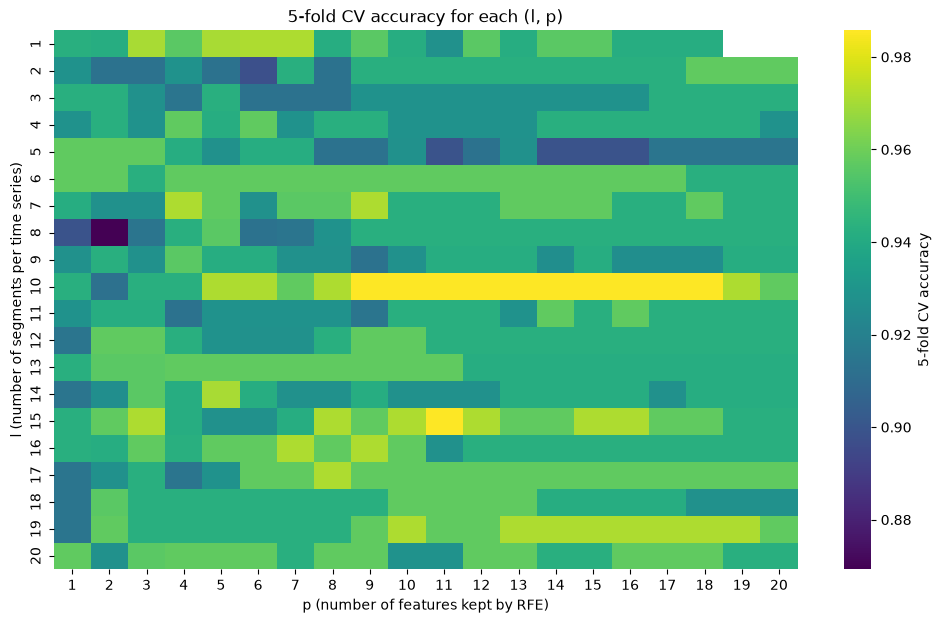

In [21]:
heat = cv_results.pivot(index="l", columns="p", values="cv_acc")

plt.figure(figsize=(12, 7))
sns.heatmap(heat, cmap="viridis", annot=False, cbar_kws={"label": "5-fold CV accuracy"})
plt.title("5-fold CV accuracy for each (l, p)")
plt.xlabel("p (number of features kept by RFE)")
plt.ylabel("l (number of segments per time series)")
plt.show()

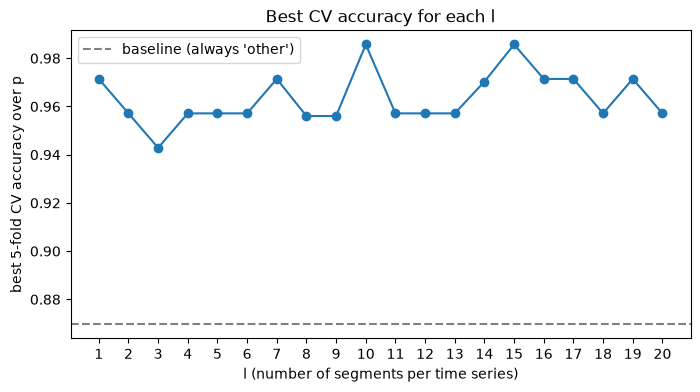

In [22]:
best_per_l = cv_results.groupby("l")["cv_acc"].max()

plt.figure(figsize=(8, 4))
plt.plot(best_per_l.index, best_per_l.values, marker="o")
plt.axhline(60/69, color="gray", linestyle="--", label="baseline (always 'other')")
plt.xticks(range(1, 21))
plt.xlabel("l (number of segments per time series)")
plt.ylabel("best 5-fold CV accuracy over p")
plt.title("Best CV accuracy for each l")
plt.legend()
plt.show()

**Setup.**

- For each l ∈ {1, …, 20}, each time series is split into l parts, and the
  three statistics selected in 1(c)iv (mean, std, max) are computed for each
  part, giving 3 × 6 × l = 18l features per instance. Only these three
  statistics are used to stay consistent with 1(c)iv and to keep the number
  of features manageable for 69 training instances.
- Features are standardized, and recursive feature elimination (RFE) with
  logistic regression is used for feature selection, since the question asks
  to choose p, the number of features kept by RFE. Standardization is needed
  because RFE ranks features by the absolute values of their coefficients.
- Regularization is removed by setting `C=np.inf` (in scikit-learn ≥ 1.8,
  `penalty=None` is deprecated). `max_iter=1000` limits the number of
  iterations; convergence warnings are suppressed during the search because
  with many features the classes can often be separated perfectly within a
  training fold (see 2(a)vi).

**The right and wrong way to do cross-validation.**

- *Wrong way:* select features (with RFE or p-values) using all 69 training
  instances, and then run cross-validation only on the logistic regression
  with the selected features. The validation folds have then already been
  used to choose the features, so the CV accuracy is overly optimistic.
- *Right way:* every step that learns from data is repeated inside each fold
  using only the training part of that fold: standardization (mean and std),
  RFE, and fitting the logistic regression. The validation part is used only
  for evaluation. Feature extraction for a given l can be done beforehand,
  because it is computed separately for each instance and does not learn
  anything from other instances.

**Stratified cross-validation.** The training set has only 9 bending and
60 other instances. With ordinary random folds, some folds could contain
very few or no bending instances. Stratified 5-fold CV keeps the class
proportions the same in every fold, so each validation fold contains 1–2
bending instances.

**Implementation.** For each l and each fold, RFE is run once down to a single
feature to get the full elimination order, and the top p features are used
for each p. This gives exactly the same features as running RFE separately
for each p, because the elimination path does not depend on where RFE stops.
As a check, the result for (l, p) = (1, 5) matches the value obtained with a
scikit-learn Pipeline and `cross_val_score` (0.9703).

**Results.** The best pair is **(l, p) = (10, 9)** with a 5-fold CV accuracy of
**0.9857**. When several pairs have the same accuracy, the one with the
smallest p (and then the smallest l) is chosen, since a simpler model is less
likely to overfit. The best p is well below the upper limit of 20, so the
limit did not affect the result.

From the heatmap:

- For l = 10, every p from 9 to 18 reaches the highest accuracy, so this
  result is stable over a wide range of p rather than a single lucky value.
- Almost all pairs have an accuracy above 0.92, much higher than the baseline
  of 0.870 obtained by always predicting "other".
- The accuracy does not change systematically with l. Differences between
  most pairs correspond to only 1–3 misclassified instances out of 69, so
  part of the variation is likely due to the small sample size.

#### iv. Confusion Matrix

In [23]:
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

In [24]:
# Refit the final model on all 69 training instances with the best (l, p).
# Warnings are NOT suppressed here, to see whether the fit converges.

X_train_df, y_train = get_xy(best_l)
scaler_final = StandardScaler().fit(X_train_df)
X_train_s = scaler_final.transform(X_train_df)

rfe_final = RFE(LogisticRegression(C=np.inf, max_iter=1000),
                n_features_to_select=best_p).fit(X_train_s, y_train)

selected_cols = list(X_train_df.columns[rfe_final.support_])
X_train_sel = X_train_s[:, rfe_final.support_]

lr_final = LogisticRegression(C=np.inf, max_iter=1000).fit(X_train_sel, y_train)

print("Selected features:", selected_cols)
print("Training accuracy:", lr_final.score(X_train_sel, y_train))

Selected features: ['max5', 'mean7', 'mean11', 'max17', 'max24', 'std27', 'std31', 'std45', 'mean59']
Training accuracy: 1.0


In [25]:
y_train_pred = lr_final.predict(X_train_sel)
cm = confusion_matrix(y_train, y_train_pred)

pd.DataFrame(cm,
             index=["true other (0)", "true bending (1)"],
             columns=["pred other (0)", "pred bending (1)"])

,pred other (0),pred bending (1)
true other (0),60,0
true bending (1),0,9


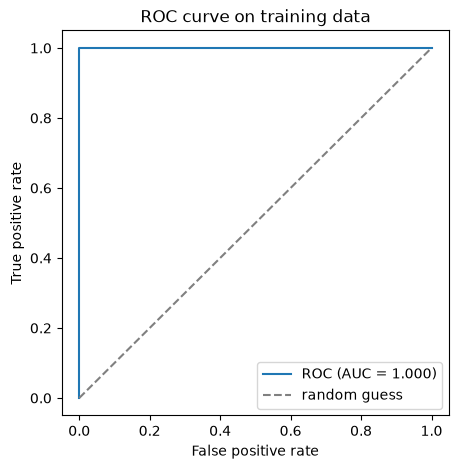

In [26]:
y_train_prob = lr_final.predict_proba(X_train_sel)[:,1]
fpr, tpr, _ = roc_curve(y_train, y_train_prob)
auc_train = roc_auc_score(y_train, y_train_prob)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_train:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve on training data")
plt.legend()
plt.show()

In [27]:
# p-values: statsmodels fits the same unregularized logistic regression
# on the same standardized, selected features (with an intercept).

X_sm = sm.add_constant(pd.DataFrame(X_train_sel, columns=selected_cols, index=y_train.index))
sm_model = sm.Logit(y_train, X_sm).fit(method="bfgs", maxiter=1000, disp=0)

coef_table = pd.DataFrame({
    "coef (statsmodels)": sm_model.params,
    "std err": sm_model.bse,
    "p-value": sm_model.pvalues,
    "coef (sklearn)": np.r_[lr_final.intercept_, lr_final.coef_.ravel()],
})
coef_table.round(4)

,coef (statsmodels),std err,p-value,coef (sklearn)
const,-12.6111,168.4331,0.9403,-7.9542
max5,3.3085,212.1288,0.9876,2.5459
mean7,-2.3894,69.4943,0.9726,-2.0607
mean11,4.6617,240.0669,0.9845,2.4926
max17,4.6395,224.3188,0.9835,3.5348
max24,-3.1909,226.1435,0.9887,-1.8202
std27,-2.4700,113.5306,0.9826,-2.2719
std31,-2.7989,159.1073,0.9860,-2.6113
std45,-2.9973,147.4950,0.9838,-1.6690
mean59,3.3555,186.5127,0.9856,2.5294


In [28]:
lr_strict = LogisticRegression(C=np.inf, max_iter=100000, tol=1e-10).fit(X_train_sel, y_train)
pd.DataFrame({"coef (default tol)": np.r_[lr_final.intercept_, lr_final.coef_.ravel()],
              "coef (tol=1e-10)":   np.r_[lr_strict.intercept_, lr_strict.coef_.ravel()]},
             index=["const"] + selected_cols).round(2)

,coef (default tol),coef (tol=1e-10)
const,-7.95,-23.16
max5,2.55,7.87
mean7,-2.06,-6.05
mean11,2.49,6.84
max17,3.53,9.40
max24,-1.82,-4.54
std27,-2.27,-6.87
std31,-2.61,-8.32
std45,-1.67,-4.29
mean59,2.53,7.93


**Final model.** Using the best pair (l, p) = (10, 9) from 2(a)iii, the
features of all 69 training instances are standardized, RFE selects 9 of the
180 features, and an unregularized logistic regression is fitted on them.

The selected features are `max5`, `mean7`, `mean11`, `max17`, `max24`,
`std27`, `std31`, `std45`, and `mean59`. Feature k corresponds to segment
(k − 1) // 6 + 1 and series (k − 1) % 6 + 1. Eight of the nine come from the
average-signal series (avg_rss12, avg_rss13, avg_rss23), which agrees with
the scatter plots in 2(a)i: the variance series separate dynamic from static
activities, but not bending from the static activities. Since the classes are
perfectly separated (see below), the exact choice of features should not be
over-interpreted.

**Confusion matrix (training data).** All 60 "other" and all 9 bending
instances are classified correctly (accuracy, sensitivity, and specificity
are all 1.0).

**ROC and AUC (training data).** The ROC curve goes straight up to a true
positive rate of 1 at a false positive rate of 0, and AUC = 1.000: every
bending instance receives a higher predicted probability than every "other"
instance.

These results are on the training data, which was used to fit the model, so
they are optimistic. Performance on the test set is examined in 2(a)v.

**Coefficients and p-values.** scikit-learn does not report p-values, so the
same unregularized logistic regression is fitted with statsmodels on the same
standardized features. The table reports the coefficients, standard errors,
and p-values from statsmodels, together with the coefficients from
scikit-learn.

Because the training data are perfectly separated, the maximum likelihood
estimates do not exist, and these numbers must be interpreted with caution:

- The standard errors (about 69–240) are many times larger than the
  coefficients, and all p-values are between 0.94 and 0.99. Taken at face
  value, none of the features would be significant, which contradicts the
  perfect classification of the training data. The p-values are therefore
  not reliable.
- The coefficients from statsmodels and scikit-learn differ noticeably (e.g.
  the intercept is −12.61 vs. −7.95), because the likelihood keeps increasing
  as the coefficients grow and each library stops at a different point. Only
  the signs of the coefficients agree.
- Refitting the scikit-learn model with a much stricter tolerance
  (`tol=1e-10`, `max_iter=100000`) makes all coefficients about three times
  larger (e.g. the intercept goes from −7.95 to −23.16) while keeping the same
  signs and roughly the same ratios between them. The optimizer keeps moving in
  the same direction and the coefficients grow without bound, so their
  magnitudes are arbitrary. Only the direction of the coefficient vector,
  which determines the decision boundary, is meaningful.

#### v. Test Classifier

In [29]:
X_test_df, y_test = get_xy(best_l, split="test")
print("Test set shape:", X_test_df.shape, "| number of bending:", y_test.sum())

# the test features must have exactly the same columns, in the same order, as the training features
assert list(X_test_df.columns) == list(X_train_df.columns)

X_test_s = scaler_final.transform(X_test_df)       # standardize with the TRAINING mean and std
X_test_sel = X_test_s[:, rfe_final.support_]       # keep the same 9 features selected on the training set

Test set shape: (19, 180) | number of bending: 4


In [30]:
y_test_pred = lr_final.predict(X_test_sel)
y_test_prob = lr_final.predict_proba(X_test_sel)[:, 1]

test_acc = lr_final.score(X_test_sel, y_test)
print(f"Test accuracy:        {test_acc:.4f}")
print(f"5-fold CV accuracy:   {best['cv_acc']:.4f}")
print(f"Baseline ('other'):   {15/19:.4f}")

Test accuracy:        1.0000
5-fold CV accuracy:   0.9857
Baseline ('other'):   0.7895


In [31]:
0.025 ** (1/19)   # lower bound of the 95% CI for accuracy when all 19 are correct

0.8235330881930346

In [32]:
cm_test = confusion_matrix(y_test, y_test_pred)
pd.DataFrame(cm_test,
             index=["true other (0)", "true bending (1)"],
             columns=["pred other (0)", "pred bending (1)"])

,pred other (0),pred bending (1)
true other (0),15,0
true bending (1),0,4


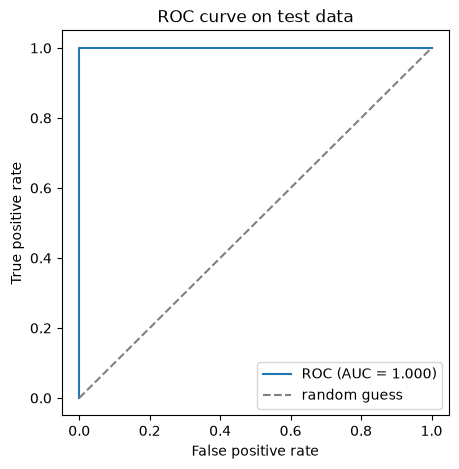

In [33]:
fpr_te, tpr_te, _ = roc_curve(y_test, y_test_prob)
auc_test = roc_auc_score(y_test, y_test_prob)

plt.figure(figsize=(5, 5))
plt.plot(fpr_te, tpr_te, label=f"ROC (AUC = {auc_test:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve on test data")
plt.legend()
plt.show()

**Test results.** The test instances are processed exactly like the training
instances: each time series is split into l = 10 parts, the same statistics
are extracted, the features are standardized with the mean and standard
deviation learned on the training set, the same 9 features selected by RFE
are kept, and the fitted logistic regression is used to predict. No step is
refitted on the test data.

| | Accuracy |
|---|---|
| Test set (19 instances: 4 bending, 15 other) | 1.0000 |
| 5-fold CV on the training set | 0.9857 |
| Baseline on the test set (always predict "other") | 0.7895 |

All 19 test instances are classified correctly (the confusion matrix has
15 true negatives and 4 true positives, with no errors), and the test AUC
is 1.0.

**Comparison with cross-validation.** The test accuracy is very close to the
CV accuracy: the difference corresponds to about one instance. Both estimates
indicate that the classifier generalizes well to new data, even though the
training data are perfectly separated. The test accuracy being slightly
higher than the CV accuracy should not be over-interpreted. The test set is
very small (only 4 bending instances), so each instance changes the accuracy
by about 5 percentage points. For example, with 19 out of 19 correct, the
95% exact (Clopper–Pearson) confidence interval for the true accuracy only
goes down to about 0.82.

#### vi. Separation

**Yes.** The classes are well separated, and this makes the estimation of the
logistic regression parameters unstable.

When two classes can be separated perfectly by a hyperplane, the likelihood of
a logistic regression keeps increasing as the coefficients grow along the
separating direction, so the maximum likelihood estimates do not exist. The
optimizer stops only because it reaches `max_iter` or a small gradient, and
the point where it stops is arbitrary. Our results show all the signs of this:

- **Perfect separation.** With the 9 selected features, the final model
  classifies all 69 training instances correctly (training accuracy 1.0,
  AUC 1.000), so the training data are linearly separable.
- **Unreliable standard errors and p-values.** The statsmodels standard errors
  (about 69–240) are many times larger than the coefficients, and all
  p-values are between 0.94 and 0.99, which contradicts the perfect
  classification.
- **Coefficients depend on the optimizer.** statsmodels and scikit-learn give
  noticeably different coefficients (e.g. intercept −12.61 vs. −7.95), and a
  stricter stopping tolerance makes all scikit-learn coefficients about three
  times larger, with the same signs and roughly the same ratios.
- **Convergence problems during cross-validation.** Many folds and (l, p)
  pairs in 2(a)iii produced convergence warnings, showing that separation
  also occurs within the training folds.

This is not in conflict with the scatter plots in 2(a)i and 2(a)ii, where no
pair of features separates the classes. With more features it becomes much
easier to find a separating hyperplane, and with 180 candidate features for
only 69 instances, RFE can easily find 9 features that separate them.

The separation makes the *parameters* unstable, but not the *predictions*.
The classification depends only on the direction of the coefficient vector,
which is stable, and the classifier performs well on new data (CV accuracy
0.9857, test accuracy 1.0). However, the coefficients and p-values cannot be
used to interpret the model. Limiting `max_iter`, as suggested, avoids
numerical problems but still gives arbitrary coefficient values. A better
remedy is regularization, such as the L1-penalized logistic regression in
2(b), which keeps the coefficients finite and unique.

#### vii. Imbalance

In [34]:
y_train_arr = y_train.to_numpy()

rng_cc = np.random.default_rng(56)
case_idx = np.where(y_train_arr == 1)[0]                     # all 9 bending instances
control_idx = rng_cc.choice(np.where(y_train_arr == 0)[0],   # 9 randomly chosen "other" instances
                            size=len(case_idx), replace=False)
cc_idx = np.concatenate([case_idx, control_idx])

X_cc, y_cc = X_train_sel[cc_idx], y_train_arr[cc_idx]
lr_cc = LogisticRegression(C=np.inf, max_iter=1000).fit(X_cc, y_cc)

print("Case-control sample size:", len(cc_idx), "| bending:", y_cc.sum())

Case-control sample size: 18 | bending: 9


In [35]:
pi = y_train_arr.mean()      # proportion of bending in the full training set (9/69)
pi_cc = y_cc.mean()          # proportion of bending in the case-control sample (9/18)

b0_raw = lr_cc.intercept_[0]
b0_adj = b0_raw + np.log(pi / (1 - pi)) - np.log(pi_cc / (1 - pi_cc))
coef_cc = lr_cc.coef_.ravel()

print(f"pi = {pi:.4f}, pi_cc = {pi_cc:.4f}")
print(f"Intercept before adjustment: {b0_raw:.4f}")
print(f"Intercept after adjustment:  {b0_adj:.4f}")

pd.DataFrame({"coef (case-control)": np.r_[b0_adj, coef_cc]},
             index=["const (adjusted)"] + selected_cols).round(4)

pi = 0.1304, pi_cc = 0.5000
Intercept before adjustment: -6.8280
Intercept after adjustment:  -8.7252


,coef (case-control)
const (adjusted),-8.7252
max5,2.5524
mean7,-1.9024
mean11,1.9511
max17,3.8599
max24,-2.9622
std27,-2.6051
std31,-1.2297
std45,-1.8183
mean59,3.1820


In [36]:
results_cc = {}
for name, X_eval, y_eval in [("train", X_train_sel, y_train), ("test", X_test_sel, y_test)]:
    z = X_eval @ coef_cc + b0_adj                  # linear predictor with the adjusted intercept
    prob = 1 / (1 + np.exp(-z))                    # predicted probability of bending
    pred = (prob > 0.5).astype(int)                # classify with threshold 0.5
    results_cc[name] = (y_eval, prob)

    print(f"--- {name} set ---")
    print(pd.DataFrame(confusion_matrix(y_eval, pred),
                       index=["true other (0)", "true bending (1)"],
                       columns=["pred other (0)", "pred bending (1)"]))
    print(f"Accuracy: {(pred == y_eval.to_numpy()).mean():.4f}, "
          f"AUC: {roc_auc_score(y_eval, prob):.4f}\n")

--- train set ---
                  pred other (0)  pred bending (1)
true other (0)                60                 0
true bending (1)               0                 9
Accuracy: 1.0000, AUC: 1.0000

--- test set ---
                  pred other (0)  pred bending (1)
true other (0)                15                 0
true bending (1)               1                 3
Accuracy: 0.9474, AUC: 1.0000



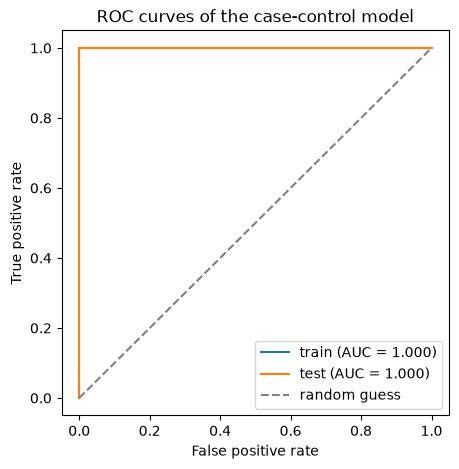

In [37]:
plt.figure(figsize=(5, 5))
for name, (y_eval, prob) in results_cc.items():
    fpr_cc, tpr_cc, _ = roc_curve(y_eval, prob)
    plt.plot(fpr_cc, tpr_cc, label=f"{name} (AUC = {roc_auc_score(y_eval, prob):.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves of the case-control model")
plt.legend()
plt.show()

**Class imbalance.** Yes, the classes are imbalanced: the training set has
60 "other" and 9 bending instances (13% bending), and the test set has 15 and
4 (21% bending). Although our classifier makes no errors on either set, the
imbalance shows up elsewhere: always predicting "other" already gives an
accuracy of 0.870 on the training set, and stratified folds are needed so
that every fold contains bending instances.

**Case-control sampling.** All 9 bending instances (cases) are kept, and
9 of the 60 "other" instances (controls) are sampled at random without
replacement, giving a balanced sample of 18 instances. A logistic regression
is fitted on this sample using the same 9 standardized features as the final
model ($l = 10$). With only 18 instances and 9 features, this sample is also
perfectly separable, so its coefficients are again unstable; the purpose here
is to illustrate the method.

In a case-control sample, the slope coefficients are estimated correctly,
but the intercept is biased, because the proportion of cases in the sample
($\tilde\pi = 0.5$) differs from the proportion in the population. Using the
training proportion $\pi = 9/69 \approx 0.1304$ as the population proportion,
the intercept is adjusted as

$$\hat\beta_0^* = \hat\beta_0 + \log\frac{\pi}{1-\pi} - \log\frac{\tilde\pi}{1-\tilde\pi},$$

which lowers it by about 1.90, from $-6.8280$ to $-8.7252$. The slopes are
unchanged by the adjustment. All nine slopes have the same signs as in the
final model of 2(a)iv and are of similar size, which agrees with the fact
that case-control sampling does not affect the slopes. (Since both samples
are perfectly separable, only the signs and rough sizes, not the exact
values, can be compared.)

**Results of the adjusted model.**

| | Accuracy | AUC | Errors |
|---|---|---|---|
| Training set (69) | 1.0000 | 1.000 | none |
| Test set (19) | 0.9474 | 1.000 | 1 bending predicted as "other" |

On the test set the AUC is still 1.0, so every bending instance is ranked
above every "other" instance, yet one bending instance is misclassified.
This is caused by the intercept adjustment: it lowers all predicted
probabilities so that they reflect the true proportion of bending (13%)
rather than the 50% in the case-control sample, and this bending instance
falls just below the 0.5 threshold. The adjustment makes the probabilities
more realistic but the classifier more conservative in predicting the rare
class. If missing bending instances is costly, a lower threshold could be
used. The result also depends on which 9 controls happen to be sampled.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate

In [39]:
C_GRID = np.logspace(-2, 2, 25)

rows_l1 = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for l in range(1,21):
        X,y = get_xy(l)

        for c in C_GRID:
            pipel1 = Pipeline([
                ("scale", StandardScaler()),
                ("clf", LogisticRegression(l1_ratio = 1, C = c, solver = "liblinear", random_state = 56 )),
            ])
            cv_out = cross_validate(pipel1, X, y, cv = skf, scoring = "accuracy", return_estimator = True)
            n_nonzero = [np.sum(est.named_steps["clf"].coef_ != 0)
                         for est in cv_out["estimator"]]
            rows_l1.append({"l": l, "C": c,
                            "cv_acc": cv_out["test_score"].mean(),
                            "avg_n_features": np.mean(n_nonzero)})

cv_l1 = pd.DataFrame(rows_l1)
cv_l1.shape

(500, 4)

In [40]:
cv_l1[cv_l1["l"] == 1].round(4)

,l,C,cv_acc,avg_n_features
0,1,0.0100,0.8703,0.0
1,1,0.0147,0.8703,0.0
2,1,0.0215,0.8703,0.0
3,1,0.0316,0.8703,0.0
4,1,0.0464,0.8703,0.0
5,1,0.0681,0.8703,0.2
6,1,0.1000,0.8846,1.2
7,1,0.1468,0.9429,1.2
8,1,0.2154,0.9714,1.8
9,1,0.3162,0.9560,2.4


In [41]:
best_l1 = cv_l1.sort_values(["cv_acc", "C", "l"],
                            ascending=[False, True, True]).iloc[0]
best_l1_l, best_l1_C = int(best_l1["l"]), best_l1["C"]
print(f"Best (l, C) = ({best_l1_l}, {best_l1_C:.4f}), CV accuracy = {best_l1['cv_acc']:.4f}, "
      f"avg number of features = {best_l1['avg_n_features']:.1f}")
print("Is the best C at the boundary?", best_l1_C in (C_GRID[0], C_GRID[-1]))

Best (l, C) = (12, 0.4642), CV accuracy = 0.9857, avg number of features = 6.4
Is the best C at the boundary? False


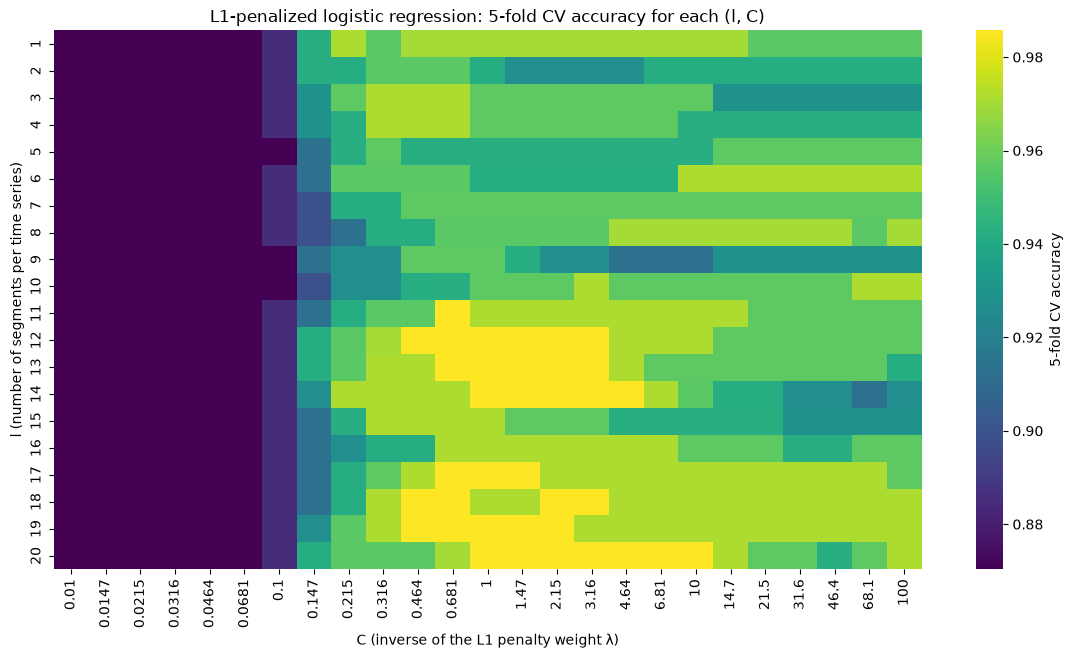

In [42]:
heat_l1 = cv_l1.pivot(index="l", columns="C", values="cv_acc")
heat_l1.columns = [f"{c:.3g}" for c in heat_l1.columns]   # shorter column labels

plt.figure(figsize=(14, 7))
sns.heatmap(heat_l1, cmap="viridis", cbar_kws={"label": "5-fold CV accuracy"})
plt.title("L1-penalized logistic regression: 5-fold CV accuracy for each (l, C)")
plt.xlabel("C (inverse of the L1 penalty weight λ)")
plt.ylabel("l (number of segments per time series)")
plt.show()

In [43]:
cv_l1[cv_l1["l"] == best_l1_l].round(4)

,l,C,cv_acc,avg_n_features
275,12,0.0100,0.8703,0.0
276,12,0.0147,0.8703,0.0
277,12,0.0215,0.8703,0.0
278,12,0.0316,0.8703,0.0
279,12,0.0464,0.8703,0.0
280,12,0.0681,0.8703,0.2
281,12,0.1000,0.8846,1.0
282,12,0.1468,0.9418,1.4
283,12,0.2154,0.9560,3.6
284,12,0.3162,0.9703,4.8


**Final L1 model on the training and test sets**

In [44]:
X_train_l1_df, y_train_l1 = get_xy(best_l1_l)
X_test_l1_df,  y_test_l1  = get_xy(best_l1_l, split="test")
assert list(X_test_l1_df.columns) == list(X_train_l1_df.columns)

pipe_l1_final = Pipeline([
    ("scale", StandardScaler()),
    ("clf",   LogisticRegression(l1_ratio=1, C=best_l1_C, solver="liblinear", random_state=56)),
]).fit(X_train_l1_df, y_train_l1)

coef_l1 = pd.Series(pipe_l1_final.named_steps["clf"].coef_.ravel(),
                    index=X_train_l1_df.columns)
nonzero_l1 = coef_l1[coef_l1 != 0]

print("Number of features:", len(coef_l1))
print("Number of nonzero coefficients:", len(nonzero_l1))
print("Intercept:", round(pipe_l1_final.named_steps["clf"].intercept_[0], 4))
nonzero_l1.round(4)

Number of features: 216
Number of nonzero coefficients: 4
Intercept: -2.3537


mean11    1.7060
max37    -0.4720
mean65    0.1504
max66    -0.4308
dtype: float64

In [45]:
for name, X_eval, y_eval in [("train", X_train_l1_df, y_train_l1),
                             ("test",  X_test_l1_df,  y_test_l1)]:
    pred = pipe_l1_final.predict(X_eval)
    prob = pipe_l1_final.predict_proba(X_eval)[:, 1]
    print(f"--- {name} set ---")
    print(pd.DataFrame(confusion_matrix(y_eval, pred),
                       index=["true other (0)", "true bending (1)"],
                       columns=["pred other (0)", "pred bending (1)"]))
    print(f"Accuracy: {(pred == y_eval.to_numpy()).mean():.4f}, "
          f"AUC: {roc_auc_score(y_eval, prob):.4f}\n")

--- train set ---
                  pred other (0)  pred bending (1)
true other (0)                60                 0
true bending (1)               0                 9
Accuracy: 1.0000, AUC: 1.0000

--- test set ---
                  pred other (0)  pred bending (1)
true other (0)                15                 0
true bending (1)               1                 3
Accuracy: 0.9474, AUC: 0.9833



**Setup.** The same features as in 2(a)iii are used (mean, std, max of each
of the l parts of the 6 series, i.e. 18l features), with the same stratified
5-fold splits, so that the two methods can be compared fairly. Instead of RFE,
an L1-penalized logistic regression (`l1_ratio=1`, solver `liblinear`) is
used. The L1 penalty shrinks many coefficients exactly to zero, so it selects
features automatically. Features are standardized so that the penalty treats
all features equally. Standardization and the L1 model are placed in a
Pipeline, so in each fold they are fitted on the training part only (the
right way to do cross-validation).

Both l ∈ {1, …, 20} and C = 1/λ are chosen by cross-validation. C is taken
from 25 values between 0.01 and 100 on a log scale. When several pairs have
the same accuracy, the one with the smallest C (strongest penalty, fewest
features) and then the smallest l is chosen.

**Results of cross-validation.** The best pair is **(l, C) = (12, 0.4642)**
with a CV accuracy of **0.9857**, using 6.4 features on average across folds.
The best C is not at the boundary of the grid.

- For C ≤ 0.068, every l gives 0.870: the penalty is so strong that all
  coefficients are zero, and the model always predicts "other".
- For l = 12, the accuracy rises quickly as C increases, stays at 0.9857 for
  C from 0.46 to 3.16 (6–11 features), and then drops to 0.971 and 0.957 as C
  grows further and more features (up to about 19 of 216) are kept. This is
  the bias-variance trade-off: too strong a penalty underfits, too weak a
  penalty overfits.
- The highest accuracy is reached over a broad region of (l, C), mainly
  l = 11–14 and 17–20 with moderate C, rather than in a single row as with
  RFE.

**Final L1 model.** Refitted on all 69 training instances with
(l, C) = (12, 0.4642), the model keeps only 4 of the 216 features
(`mean11`, `max37`, `mean65`, `max66`), three of which come from the
average-signal series. The intercept is −2.35 and the coefficients range from
−0.47 to 1.71. Unlike the unregularized model, the coefficients are finite and
uniquely determined, even though the model still classifies all training
instances correctly: the penalty prevents them from growing without bound.

| | Accuracy | AUC | Errors |
|---|---|---|---|
| Training set (69) | 1.0000 | 1.000 | none |
| Test set (19) | 0.9474 | 0.983 | 1 bending predicted as "other" |

#### ii. Comparison

In 2(a)iii, backward selection with RFE was used instead of p-values, which
the question allows as an alternative. The comparison below covers RFE, and
also the p-value approach itself.

| | RFE (2(a)) | L1 penalty (2(b)) |
|---|---|---|
| Best parameters | l = 10, p = 9 | l = 12, C = 0.4642 |
| CV accuracy | 0.9857 | 0.9857 |
| Features in the final model | 9 | 4 |
| Test accuracy | 1.0000 | 0.9474 |
| Test AUC | 1.000 | 0.983 |
| Coefficients | grow without bound | finite and unique |

**Which one performs better?** In terms of prediction, the two methods perform
about the same. Their CV accuracies are identical, and the difference on the
test set is a single instance out of 19, which is within the uncertainty of
such a small test set. However, the L1-penalized model is better in other
respects: it uses fewer than half as many features (4 vs. 9), its coefficients
are finite and well defined, and its best CV accuracy is reached over a broad
range of (l, C) rather than for a single l, so it is less sensitive to the
choice of tuning parameters. Selecting variables by p-values would be even
less reliable here: because the data are perfectly separable, the p-values in
2(a)iv are all between 0.94 and 0.99 and give no useful information about
which features matter.

**Which one is easier to implement?** L1 regularization is easier. Feature
selection happens while the model is fitted, there is only one continuous
tuning parameter (C), and the whole procedure fits naturally into a scikit-learn
Pipeline with standard cross-validation, so it is easy to do cross-validation
the right way. It is also fast with `liblinear`. Selection by p-values requires
repeated fitting and pruning, and scikit-learn does not provide p-values, so
another package (statsmodels) is needed. RFE also requires many refits: to
keep the cross-validation fast enough, a custom cross-validation loop and the
ranking trick were needed.

Overall, L1-penalized logistic regression is preferable for this problem.

### (c) Multi-class Classification (The Realistic Case)

#### i. L1-penalized multinomial logistic regression

In [46]:
def get_xy_multi(l, split="train"):
    """Same features as get_xy, but y is the activity name (7 classes)."""
    feat = extract_features(records, n_segments=l)
    feat = feat[feat["split"] == split]
    cols = [c for c in feat.columns if re.sub(r"\d+$", "", c) in selected_stats]
    return feat[cols], feat["activity"]

X, y = get_xy_multi(1)
print(X.shape)
y.value_counts()

(69, 18)


activity
cycling     12
lying       12
sitting     12
standing    12
walking     12
bending1     5
bending2     4
Name: count, dtype: int64

In [47]:
# test pipeline
import time

X,y = get_xy_multi(1)
pipe_multi = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(l1_ratio = 1, C = 1.0, solver = "saga", max_iter = 5000, random_state = 56)),
])

start = time.time()
scores = cross_val_score(pipe_multi, X, y, cv = skf, scoring = "accuracy")
print("mean cv accuracy:",scores.mean().round(4))
print("Time(seconds):", round(time.time() - start,2))

mean cv accuracy: 0.9121
Time(seconds): 0.06


/Users/non-sense/miniconda3/envs/dsci552/lib/python3.12/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


In [48]:
rows_multi = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    warnings.filterwarnings("ignore", message="The least populated class")

    for l in range(1,21):
        X,y = get_xy_multi(l)
        for c in C_GRID:
            pipe_multi = Pipeline([
                ("scale", StandardScaler()),
                ("clf", LogisticRegression(l1_ratio = 1, C = c, solver = "saga", max_iter = 5000, random_state = 56)),
            ])
            cv_out = cross_validate(pipe_multi, X, y, cv = skf, scoring = "accuracy", return_estimator = True)
            n_used = [np.any(est.named_steps["clf"].coef_ != 0,axis = 0).sum()
                      for est in cv_out["estimator"]]
            rows_multi.append({"l": l, "C":c, "cv_acc": cv_out["test_score"].mean(), "avg_n_features": np.mean(n_used)})


In [49]:
cv_multi = pd.DataFrame(rows_multi)
print(cv_multi.shape)
cv_multi.tail()

(500, 4)


,l,C,cv_acc,avg_n_features
495,20,21.544347,0.752747,238.0
496,20,31.622777,0.752747,270.6
497,20,46.415888,0.752747,299.2
498,20,68.129207,0.767033,328.0
499,20,100.000000,0.767033,350.2


In [50]:
#find best (l,C)

best_multi = cv_multi.sort_values(["cv_acc", "C", "l"],ascending = [False, True, True]).iloc[0]
best_multi_l, best_multi_C = int(best_multi["l"]), best_multi["C"]

print(f"Best (l,C) = ({best_multi_l},{best_multi_C:.4f}),"
      f"CV accuracy = {best_multi['cv_acc']:.4f},"
      f" avg number of features = {best_multi['avg_n_features']:.1f}")
print("Is the best C at the boundary?", best_multi_C in (C_GRID[0], C_GRID[-1]))

Best (l,C) = (1,1.0000),CV accuracy = 0.9121, avg number of features = 12.0
Is the best C at the boundary? False


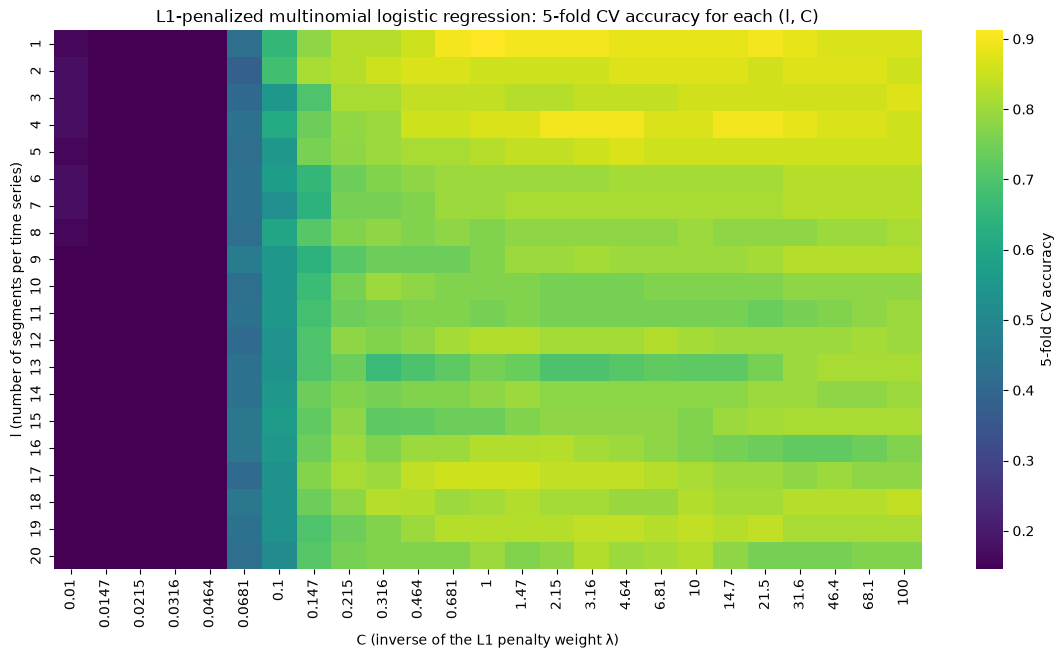

In [51]:
heat_multi = cv_multi.pivot(index="l", columns="C", values="cv_acc")
heat_multi.columns = [f"{c:.3g}" for c in heat_multi.columns]

plt.figure(figsize=(14, 7))
sns.heatmap(heat_multi, cmap="viridis", cbar_kws={"label": "5-fold CV accuracy"})
plt.title("L1-penalized multinomial logistic regression: 5-fold CV accuracy for each (l, C)")
plt.xlabel("C (inverse of the L1 penalty weight λ)")
plt.ylabel("l (number of segments per time series)")
plt.show()

In [52]:
cv_multi[cv_multi["l"] == best_multi_l].round(4)

,l,C,cv_acc,avg_n_features
0,1,0.0100,0.1593,0.0
1,1,0.0147,0.1451,0.0
2,1,0.0215,0.1451,0.0
3,1,0.0316,0.1451,0.0
4,1,0.0464,0.1451,0.0
5,1,0.0681,0.4209,2.4
6,1,0.1000,0.6527,4.6
7,1,0.1468,0.7813,6.6
8,1,0.2154,0.8253,8.2
9,1,0.3162,0.8253,9.0


In [53]:
#Final multinomial model: test error, confusion matrix, and ROC

X_train_m, y_train_m = get_xy_multi(best_multi_l)
X_test_m, y_test_m = get_xy_multi(best_multi_l, split = "test")
assert list(X_test_m.columns) == list(X_train_m.columns)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    pipe_multi_final = Pipeline([
        ("scale", StandardScaler()),
        ("clf",   LogisticRegression(l1_ratio=1, C=best_multi_C, solver="saga", max_iter=5000, random_state = 56)),
    ]).fit(X_train_m, y_train_m)

coef_m = pipe_multi_final.named_steps["clf"].coef_
print("Features used:", np.any(coef_m != 0, axis=0).sum(), "of", coef_m.shape[1])

for name, X_eval, y_eval in [("train", X_train_m, y_train_m),("test", X_test_m, y_test_m)]:
    acc = (pipe_multi_final.predict(X_eval) == y_eval.to_numpy()).mean()
    print(f"{name}: accuracy = {acc:.4f}, error = {1 - acc:.4f}")

Features used: 12 of 18
train: accuracy = 0.9855, error = 0.0145
test: accuracy = 0.9474, error = 0.0526


In [54]:
# confusion matrix
classes = pipe_multi_final.classes_
y_test_pred_m = pipe_multi_final.predict(X_test_m)

pd.DataFrame(confusion_matrix(y_test_m, y_test_pred_m, labels = classes),
             index = [f"true {c}" for c in classes],
             columns = [f"pred {c}" for c in classes])

,pred bending1,pred bending2,pred cycling,pred lying,pred sitting,pred standing,pred walking
true bending1,2,0,0,0,0,0,0
true bending2,0,2,0,0,0,0,0
true cycling,0,0,3,0,0,0,0
true lying,0,0,0,3,0,0,0
true sitting,0,0,0,0,3,0,0
true standing,0,0,0,0,1,2,0
true walking,0,0,0,0,0,0,3


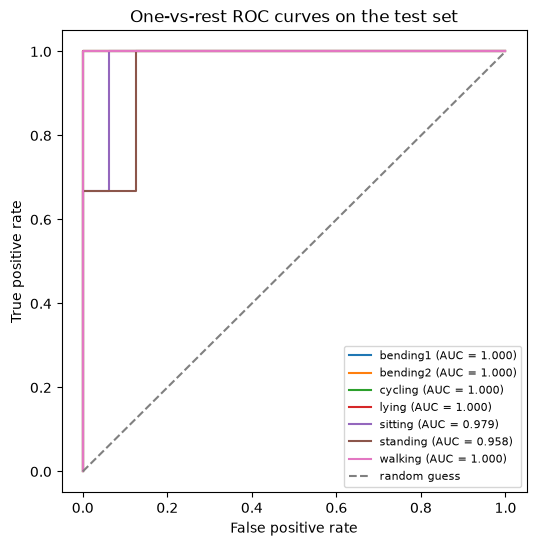

Macro-average AUC (one-vs-rest): 0.9911


In [55]:
#roc and auc

from sklearn.preprocessing import label_binarize

prob_test_m = pipe_multi_final.predict_proba(X_test_m)
y_test_bin = label_binarize(y_test_m, classes = classes)

plt.figure(figsize=(6, 6))
for k, cls in enumerate(classes):
    fpr_k, tpr_k, _ = roc_curve(y_test_bin[:, k], prob_test_m[:, k])
    auc_k = roc_auc_score(y_test_bin[:, k], prob_test_m[:, k])
    plt.plot(fpr_k, tpr_k, label=f"{cls} (AUC = {auc_k:.3f})")
plt.plot([0, 1], [0, 1], color="gray", linestyle="--", label="random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("One-vs-rest ROC curves on the test set")
plt.legend(fontsize=8)
plt.show()

macro_auc = roc_auc_score(y_test_m, prob_test_m, multi_class = "ovr", average = "macro", labels = classes)
print(f"Macro-average AUC (one-vs-rest): {macro_auc:.4f}")

**Setup.** All 7 activities are now classified (bending1, bending2, cycling,
lying, sitting, standing, walking). The same features (mean, std, max of each
of the l parts of the 6 series, 18l features) and the same stratified 5-fold
splits are used as in 2(b)i. An L1-penalized multinomial logistic regression is
fitted with the `saga` solver (`l1_ratio=1`, `max_iter=5000`), since
`liblinear` does not support the multinomial model. Standardization and the
model are placed in a Pipeline, so they are fitted only on the training part of
each fold. Both l ∈ {1, …, 20} and C (25 values from 0.01 to 100 on a log
scale) are chosen by cross-validation, with ties broken by the smallest C and
then the smallest l.

The training set has only 4 bending2 instances, fewer than the 5 folds, so one
validation fold contains no bending2 instance (scikit-learn warns about this).
The 5 folds are kept for consistency with 2(b)i.

**Cross-validation results.** The best pair is **(l, C) = (1, 1.0)**, with a
CV accuracy of **0.9121** using 12 of the 18 features on average.
The best C is not at the boundary of the grid.

- For very small C (≤ 0.046), all coefficients are zero and the CV accuracy is
  only about 0.15–0.17, close to always predicting the most common class
  (12/69 ≈ 0.17).
- For l = 1, the accuracy rises as C increases, peaks at C = 1.0 with 12
  features, and then decreases slightly to about 0.87 when all 18 features
  are used, a mild sign of overfitting.
- Unlike the binary problem, the best results are obtained for small l
  (mainly l = 1 and l = 4), and the accuracy tends to be lower for larger l.
  With 7 classes, the model has to estimate 7 sets of coefficients from only
  69 instances, so additional features from splitting make it easier to
  overfit. For example, with l = 20 and C = 100, about 350 of the 360 features
  are used and the CV accuracy drops to about 0.77.

**Final model and test error.** Refitted on all training instances with
(l, C) = (1, 1.0), the model uses 12 of the 18 features.

| | Accuracy | Error |
|---|---|---|
| Training set (69) | 0.9855 | 0.0145 |
| 5-fold CV | 0.9121 | 0.0879 |
| **Test set (19)** | **0.9474** | **0.0526** |

The **test error is 0.0526**: 18 of the 19 test instances are classified
correctly. The test accuracy is a bit higher than the CV accuracy, but the
difference corresponds to about one test instance and is within the
uncertainty of such a small test set.

**Confusion matrix (multi-class).** For K classes, the confusion matrix is a
K × K table whose entry in row i and column j is the number of instances of
true class i predicted as class j. Correct predictions lie on the diagonal,
and the off-diagonal entries show which classes are confused with each other.
On the test set, the only error is one *standing* instance predicted as
*sitting*. Both are static postures with little movement between the
sensors, so their features are similar. All other classes, including the two
similar bending activities, are classified correctly.

**ROC curves and AUC (multi-class).** ROC curves are defined for binary
problems, so for multi-class classification the one-vs-rest approach is used:
for each class, that class is treated as positive and all other classes as
negative, and an ROC curve is drawn using the predicted probability of that
class. On the test set, five classes have AUC = 1.000; sitting has
AUC = 0.979 and standing has AUC = 0.958, consistent with the confusion
between them. The macro-average AUC (the unweighted mean over the 7 classes)
is **0.9911**. Since each class has only 2–3 test instances, the ROC curves
have very few steps.

#### ii. Naive Bayes

In [56]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB

# check whether there is any negative number in the features, because multinomial naive bayes requires features are not negative.
all_nonneg = True
for l in range(1,21):
    for split in ["train", "test"]:
        X, _ = get_xy_multi(l, split = split)
        if(X < 0).any().any():
            all_nonneg = False
            print(f"Negative values found: l = {l}, {split}")
print("All features are non-negative:", all_nonneg)

All features are non-negative: True


In [57]:
rows_nb = []

with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message="The least populated class")

    for l in range(1,21):
        X,y = get_xy_multi(l)
        for model_name,model in [("Gaussian", GaussianNB()), ("Multinomial", MultinomialNB())]:
            scores = cross_val_score(model, X, y, cv = skf, scoring = "accuracy")
            rows_nb.append({"model": model_name, "l":l, "cv_acc": scores.mean()})

cv_nb = pd.DataFrame(rows_nb)
cv_nb.shape

(40, 3)

In [58]:
#find the best cv accuracy and corresponding l

best_nb = (cv_nb.sort_values(["cv_acc","l"],ascending = [False, True])
           .groupby("model").head(1))
best_nb

,model,l,cv_acc
0,Gaussian,1,0.882418
7,Multinomial,4,0.869231


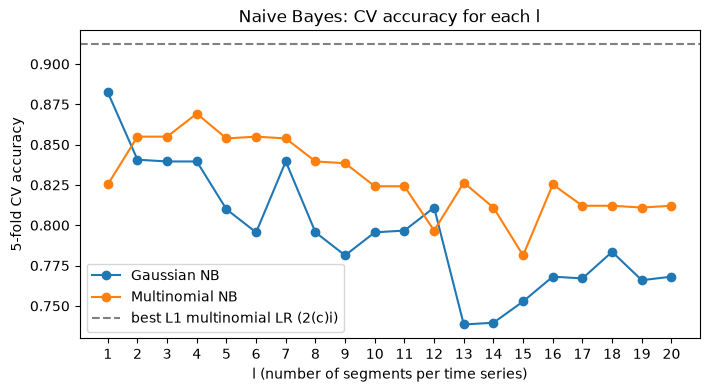

In [59]:
plt.figure(figsize=(8, 4))
for model_name in ["Gaussian", "Multinomial"]:
    sub = cv_nb[cv_nb["model"] == model_name]
    plt.plot(sub["l"], sub["cv_acc"], marker="o", label=f"{model_name} NB")
plt.axhline(cv_multi["cv_acc"].max(), color="gray", linestyle="--",
            label="best L1 multinomial LR (2(c)i)")
plt.xticks(range(1, 21))
plt.xlabel("l (number of segments per time series)")
plt.ylabel("5-fold CV accuracy")
plt.title("Naive Bayes: CV accuracy for each l")
plt.legend()
plt.show()

In [60]:
#train the final bayes model on the whole training set using the l finding in last step

nb_final = {}

for model_name, model_class in [("Gaussian", GaussianNB), ("Multinomial", MultinomialNB)]:
    l_best = int(best_nb.loc[best_nb["model"] == model_name, "l"].iloc[0])

    X_tr, y_tr = get_xy_multi(l_best)
    X_te, y_te = get_xy_multi(l_best, split="test")
    assert list(X_te.columns) == list(X_tr.columns)

    model = model_class().fit(X_tr, y_tr)
    acc_tr = model.score(X_tr, y_tr)
    acc_te = model.score(X_te, y_te)
    print(f"{model_name} NB (l = {l_best}): "
          f"train accuracy = {acc_tr:.4f}, test accuracy = {acc_te:.4f}, test error = {1 - acc_te:.4f}")

    nb_final[model_name] = (model, X_te, y_te)

Gaussian NB (l = 1): train accuracy = 0.9710, test accuracy = 0.8947, test error = 0.1053
Multinomial NB (l = 4): train accuracy = 0.9420, test accuracy = 0.8421, test error = 0.1579


In [61]:
pd.set_option("display.width", 200)
for model_name, (model, X_te, y_te) in nb_final.items():
    cls = model.classes_
    print(f"--- {model_name} NB ---")
    print(pd.DataFrame(confusion_matrix(y_te, model.predict(X_te), labels=cls),
                       index=[f"true {c}" for c in cls],
                       columns=[f"pred {c}" for c in cls]), "\n")

--- Gaussian NB ---
               pred bending1  pred bending2  pred cycling  pred lying  pred sitting  pred standing  pred walking
true bending1              2              0             0           0             0              0             0
true bending2              0              1             0           0             1              0             0
true cycling               0              0             3           0             0              0             0
true lying                 0              0             0           3             0              0             0
true sitting               0              0             0           0             3              0             0
true standing              0              0             0           0             1              2             0
true walking               0              0             0           0             0              0             3 

--- Multinomial NB ---
               pred bending1  pred bending2  pred c

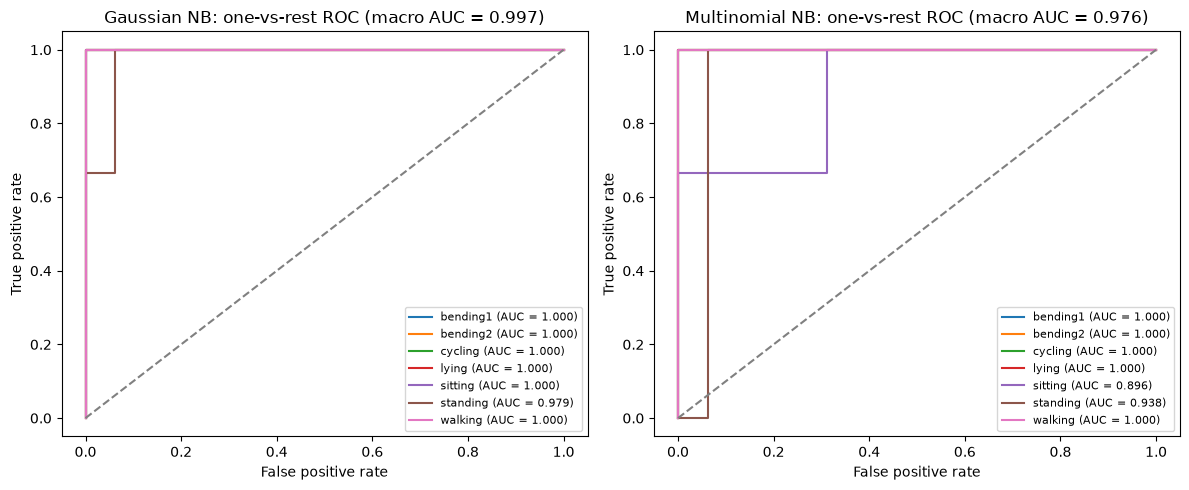

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (model_name, (model, X_te, y_te)) in zip(axes, nb_final.items()):
    cls = model.classes_
    prob = model.predict_proba(X_te)
    y_bin = label_binarize(y_te, classes=cls)
    for k, c in enumerate(cls):
        fpr_k, tpr_k, _ = roc_curve(y_bin[:, k], prob[:, k])
        ax.plot(fpr_k, tpr_k, label=f"{c} (AUC = {roc_auc_score(y_bin[:, k], prob[:, k]):.3f})")
    ax.plot([0, 1], [0, 1], color="gray", linestyle="--")
    macro = roc_auc_score(y_te, prob, multi_class="ovr", average="macro", labels=cls)
    ax.set_title(f"{model_name} NB: one-vs-rest ROC (macro AUC = {macro:.3f})")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

The same features and folds as in 2(c)i are used. Features are not standardized here,
since Multinomial NB requires non-negative inputs (all features are non-negative, as
checked above), and Gaussian NB does not need standardization.

**Cross-validation.**

| Model | Best l | CV accuracy |
|---|---|---|
| Gaussian NB | 1 | 0.8824 |
| Multinomial NB | 4 | 0.8692 |

Gaussian NB is best without splitting and its accuracy drops considerably for
larger l (to about 0.74 at l = 13–14). Multinomial NB is more stable across l
and is better than Gaussian NB for most l ≥ 2. One possible reason is that, as
l grows, Gaussian NB has to estimate a mean and a variance for many more
features from only 4–12 instances per class, and the features of neighboring
segments are strongly correlated, which violates the independence assumption.
Both models stay below the best CV accuracy of the L1 multinomial logistic
regression (0.9121) for every l.

**Test results.**

| Model | Train accuracy | Test accuracy | Test error | Macro AUC |
|---|---|---|---|---|
| Gaussian NB (l = 1) | 0.9710 | 0.8947 | 0.1053 | 0.997 |
| Multinomial NB (l = 4) | 0.9420 | 0.8421 | 0.1579 | 0.976 |

Gaussian NB misclassifies 2 of the 19 test instances (one bending2 and one
standing, both predicted as sitting), and Multinomial NB misclassifies 3
(lying → sitting, sitting → standing, standing → sitting). Both models
classify the dynamic activities (cycling, walking) correctly, and most errors
involve the static activities, especially sitting and standing, as in 2(c)i.
In the one-vs-rest ROC curves, Gaussian NB has AUC = 1 for every class except
standing (0.979), while Multinomial NB has lower AUCs for sitting (0.896) and
standing (0.938).

**Comparison.** Gaussian NB performs better than Multinomial NB: it has higher CV
accuracy, lower test error, and higher macro AUC. This is expected, since our
features are continuous measurements, which the Gaussian assumption describes
better than the count-based Multinomial model.

#### iii. Comparison

| Method | Best l | CV accuracy | Test accuracy | Test error | Macro AUC |
|---|---|---|---|---|---|
| L1 multinomial logistic regression | 1 | **0.9121** | **0.9474** | **0.0526** | 0.991 |
| Gaussian NB | 1 | 0.8824 | 0.8947 | 0.1053 | **0.997** |
| Multinomial NB | 4 | 0.8692 | 0.8421 | 0.1579 | 0.976 |

**The L1-penalized multinomial logistic regression is the best method for this
problem.** It has the highest CV accuracy and the highest test accuracy, and its
test error is half that of Gaussian NB. The CV accuracy, based on all 69
training instances, is a more reliable comparison than the test set of only
19 instances, and the logistic regression is also ahead there. Gaussian NB has
a slightly higher macro AUC (0.997 vs. 0.991), but the difference is very small
for such a small test set, and AUC measures ranking rather than the final
classification. Multinomial NB is the weakest of the three.

Some likely reasons for the advantage of the logistic regression are:

- It does not assume that the features are independent. Our features are
  strongly correlated (for example, mean and max of the same series), and
  Naïve Bayes treats correlated features as separate pieces of evidence.
- The L1 penalty selects features automatically (12 of 18 are used), which
  reduces overfitting.
- It models the class probabilities given the features directly, whereas
  Naïve Bayes must model the distribution of the features within each class,
  which is harder to get right with few instances per class.

On the other hand, Naïve Bayes is much simpler and faster and needs almost no
tuning. All three methods classify the dynamic activities perfectly, and their
errors concentrate on the static activities, especially sitting and standing.
Since the test set is small, the differences between the methods correspond to
only one or two test instances.

## 3. ISLR 4.8.3

Assume that in class $k$, $X \sim N(\mu_k, \sigma_k^2)$, so each class has its own variance.
The density of class $k$ is

$$f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

The Bayes classifier assigns $x$ to the class with the largest posterior
$p_k(x) = \pi_k f_k(x) \big/ \sum_{l} \pi_l f_l(x)$. The denominator is the same for all
classes, and the log is increasing, so it is enough to compare $\log\big(\pi_k f_k(x)\big)$:

$$\log\big(\pi_k f_k(x)\big) = \log\pi_k - \log\sqrt{2\pi} - \log\sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding the square and dropping $-\log\sqrt{2\pi}$, which is the only term that does
not depend on $k$, gives the discriminant function

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k.$$

In LDA, all classes share the same variance $\sigma^2$, so the term $-x^2/(2\sigma^2)$
is the same for every class and can be dropped, which leaves a linear function of $x$.
Here the variance depends on $k$, so $-x^2/(2\sigma_k^2)$ is different for each class and
must be kept. Therefore $\delta_k(x)$ is quadratic in $x$.

The boundary between classes $k$ and $l$ is where $\delta_k(x) = \delta_l(x)$. In this
equation, the coefficient of $x^2$ is

$$\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2},$$

which is nonzero whenever $\sigma_k^2 \neq \sigma_l^2$. So the boundary is the solution of a
quadratic equation and can consist of two points: a class with a small variance can
win in an interval around its mean, while a class with a larger variance wins on
both sides. A linear rule cannot do this, since it splits the line at only one point.

Hence the Bayes classifier is not linear but quadratic. If all variances are equal,
the $x^2$ terms cancel and we recover the linear boundary of LDA.

## 4. ISLR 4.8.7

Let $P(\text{Yes}) = 0.8$ and $P(\text{No}) = 0.2$ be the prior probabilities, and let
$f(x \mid \text{Yes})$ and $f(x \mid \text{No})$ be the normal densities of $X$ in each
group, with means 10 and 0 and common variance $\sigma^2 = 36$. By Bayes' theorem,

$$P(\text{Yes} \mid X = 4) = \frac{P(\text{Yes})\, f(4 \mid \text{Yes})}{P(\text{Yes})\, f(4 \mid \text{Yes}) + P(\text{No})\, f(4 \mid \text{No})}.$$

Since both groups have the same variance, the constant $1/\sqrt{2\pi\sigma^2}$ cancels:

$$P(\text{Yes} \mid X = 4) = \frac{0.8\, e^{-(4-10)^2/72}}{0.8\, e^{-(4-10)^2/72} + 0.2\, e^{-(4-0)^2/72}}
= \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.222}} \approx 0.752.$$

So the probability that the company issues a dividend is about **75.2%**.
Although $x = 4$ is closer to the "No" mean, the high prior (80%) dominates.

In [63]:
num = 0.8 * np.exp(-(4 - 10)**2 / 72)
den = num + 0.2 * np.exp(-(4 - 0)**2 / 72)
print(f"P(Yes | X = 4) = {num / den:.4f}")

P(Yes | X = 4) = 0.7519


## References
1. G. James, D. Witten, T. Hastie, R. Tibshirani, J. Taylor,
   *An Introduction to Statistical Learning*, Chapters 4, 5, 6.
2. F. Palumbo et al., "Human activity recognition using multisensor data fusion
   based on Reservoir Computing," *JAISE*, 2016 (AReM dataset).
3. P. Peduzzi et al., "A simulation study of the number of events per variable in
   logistic regression analysis," *J. Clin. Epidemiol.*, 1996.
4. scikit-learn documentation: `LogisticRegression`, `RFE`, `StratifiedKFold`,
   `cross_validate`, `GaussianNB`, `MultinomialNB`, `roc_curve`, `roc_auc_score`.
5. statsmodels documentation: `Logit`.